In [ ]:
                                                                                                                                                                                                                                                                                                                                # Importing the relevant libraries for the defined problem
import numpy as np
import math
from math import sqrt
import cmath
import scipy
import pandas as pd
import csv
import os
from numpy import linalg
from qutip import *
from numpy.linalg import matrix_rank
from collections import Counter
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import time
import seaborn as sns
from sklearn.metrics import confusion_matrix

# sklearn.preprocessing provides utility functions and transformer classes to change raw feature vectors into a representation that is more suitalb for downstream estimators
# LabelEncoder assigns a real number to the features which are not of number datatype
from sklearn.preprocessing import LabelEncoder   
# Keras Classifier is a wrapper functions which trains the models on subset(s) of training set, basically it tries to find that combination of features which are most important for making predictions                                               
from keras.wrappers.scikit_learn import KerasClassifier 
from keras.utils import np_utils 
#importing the libraries for modelling 
from keras.models import Sequential   # IDK
# Dense means, a neuron in a particular hidden layer is connected to every neuron in the previous layer
# Dropout means, input of some neurons in a particular layer will be set to 0 with some probability/rate  =p 
from keras.layers import Dense, Dropout, BatchNormalization 
#Stop training when a monitered metric such as 'loss' or 'accuracy' has stopped improving. 
from keras.callbacks import EarlyStopping 

from sklearn.metrics import classification_report
from tensorflow import keras

In [36]:
def array_to_label_list(Matrix,n,k):
    '''
    Matrix refers to the density matrix which is supposed to be input in this function, 
    of whose the list is to be constructed
    
    n = Number of qubits in the system
    
    k = index reference to the three qubit entanglement class 
        k = 0 => FS => Full Separable => A-B-C => [1,0,0,0,0,0]
        k = 1 => bs2 => Bi-Separable-1 => A-BC => [0,1,0,0,0,0]
        k = 2 => BS2 => Bi-Separable-2 => AB-C => [0,0,1,0,0,0]
        k = 3 => BS3 => Bi-Separable-3 => AC-B => [0,0,0,1,0,0]
        k = 4 => W => Werner State => ABC =>      [0,0,0,0,1,0]
        k = 5 => GHZ => Greenberg-Horne-Zeilinger State => ABC => [0,0,0,0,0,1]
        
    From 0 to 31 elements of the returned list real components of the density matrix(Re(rho_00),Re(rho_01),...) i.e, from 0 to N-1
    from 32 to 63 : Imaginary components of the density matrix i.e, (Im(rho_00),Im(rho_01),...) 
    from 64 to 69 : One hot encoded labels corresponding to the class of the 3 qubit entangled states
    '''
    N = 2**(2*n)
    #Matrix   = Matrix.data.toarray()
    Matrix_1 = Matrix.reshape((1,N))
    data = np.zeros((2*N))
    FS  = [0,1,0,0,0,0,0]
    bs2 = [1,0,1,0,0,0,0]
    BS2 = [2,0,0,1,0,0,0]
    BS3 = [3,0,0,0,1,0,0]
    W   = [4,0,0,0,0,1,0]
    GHZ = [5,0,0,0,0,0,1]

    for i in range(0,N):
        data[i] = np.real(Matrix_1[0][i])
    for j in range(N,2*N):
        data[j] = np.imag(Matrix_1[0][j-N])
        
    data  = data.tolist()
    
    if k == 0:
        data.extend(FS)
    elif k == 1:
        data.extend(bs2)
    elif k == 2:
        data.extend(BS2)
    elif k == 3:
        data.extend(BS3)
    elif k == 4:
        data.extend(W)
    elif k == 5:
        data.extend(GHZ)
    else :
        return "Error : Corresponding state label doesn't exist, select from 0,1,2,3,4 or 5"

    return data


def labels(n):
    
    N=2**(2*n)
    fields = [None]*((2*N))
    #list_classes_0 = ['Fully-Separable', 'Bi-Separable-1','Bi-Separable-2','Bi-Separable-3','W','GHZ']
    list_classes_1 = ['CODE','FS','BS1','BS2','BS3','W','GHZ',]
     
    k = 0 
    for i in range(2**n):
        for j in range(2**n):
            fields[k] = 'Rho_'+str(i)+'_'+str(j)+'_Real'
            k=k+1
            
    k = N
    for i in range(2**n):
        for j in range(2**n):
            fields[k] = 'Rho_'+str(i)+'_'+str(j)+'_Imag'
            k=k+1
    
    fields.extend(list_classes_1)
    
    return fields

def train_test_generator(n,m):
    
    '''
    n refers to number of examples/states you want 
    for each of the six labels or entanglement classes 
    total examples in train set = 6*n
    n < 100,000 
    
    [m - (n)] refers to number of examples/states you want 
    for each of the six labels or entanglement classes 
    total examples in test set = 6*m
    m < 60,000. I take test set size to be ~1/10 of the training set size 
    
    make sure the index of m is greater than n+1 always
    '''
    csv_path_list = []
    csv_pd_all_list = []
    csv_pd_list_train = []
    csv_pd_list_test = []
     
    for i in range(6):
        location = r"<LOCAL_DATA_DIR>\Paper Publication\ANN_PCA_DATASET\ANN\all_classes_acin_states\data_"+str(i)+"_1.csv"
        csv_path_list.append(location)

    for j in range(6):
        path = csv_path_list[j]
        #csv_pd_list_train.append(pd.read_csv(path, nrows = n,  names=labels(3)))
        csv_pd_all_list.append(pd.read_csv(path, names=labels(3), dtype = np.float64, header=0))
        #csv_pd_all_list.append(pd.read_csv(path, names=labels(3)).iloc[:,1:])
        csv_pd_all_list[j] = csv_pd_all_list[j].sample(frac=1)
        
    for k in range(6):
        csv_pd_list_train.append(csv_pd_all_list[k].iloc[:n])
        csv_pd_list_test.append(csv_pd_all_list[k].iloc[n:n+m])
    
    csv_merged_train = pd.concat([csv_pd_list_train[0],csv_pd_list_train[1],csv_pd_list_train[2],csv_pd_list_train[3],csv_pd_list_train[4],csv_pd_list_train[5]], ignore_index = True)
    csv_merged_test = pd.concat([csv_pd_list_test[0],csv_pd_list_test[1],csv_pd_list_test[2],csv_pd_list_test[3],csv_pd_list_test[4],csv_pd_list_test[5]], ignore_index = True)
    csv_merged_train.iloc[:,:134]
    csv_merged_test.iloc[:,:134]
    #csv_merged = pd.concat([csv_pd_all_list[0].iloc[:n],csv_pd_all_list[1].iloc[:n] ,csv_pd_all_list[2].iloc[:n],csv_pd_all_list[3].iloc[:n],csv_pd_all_list[4].iloc[:n],csv_pd_all_list[5].iloc[:n]], ignore_index = True)
    #x,y = train_test_generator(n=100,m=10)
    return csv_merged_train, csv_merged_test

def loss_graph(history):
    history_dict = history.history
    # Learning curve(Loss)
    # let's see the training and validation loss by epoch

    # loss
    loss_values = history_dict['loss'] # you can change this
    val_loss_values = history_dict['val_loss'] # you can also change this

    # range of X (no. of epochs)
    epochs = range(1, len(loss_values) + 1) 

    # plot
    plt.plot(epochs, loss_values, 'bo', label='Training loss')
    plt.plot(epochs, val_loss_values, 'orange', label='Validation loss')
    plt.title('Training and validation loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    #plt.show()
    return plt, np.min(val_loss_values)

def accuracy_graph(history):
    # Learning curve(accuracy)
    # let's see the training and validation accuracy by epoch

    # accuracy
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']

    # range of X (no. of epochs)
    epochs = range(1, len(acc) + 1)

    # plot
    # "bo" is for "blue dot"
    plt.plot(epochs, acc, 'bo', label='Training accuracy')
    # orange is for "orange"
    plt.plot(epochs, val_acc, 'orange', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    #plt.show()
    return plt, np.max(val_acc)
    # this is the max value - should correspond to
    # the HIGHEST train accuracy

def evaluate_model(model, x_test, y_test):
    test_evaluate = model.evaluate(x = x_test, y = y_test)
    y_test_pred = np.round(model.predict(x_test),0)
    return y_test_pred, test_evaluate

def confusion_matrix_graph(y_test, y_test_pred):
    T5_lables_1 = ['FS','BS1','BS2','BS3','W','GHZ']    
    ax= plt.subplot()

    cm = confusion_matrix(np.asarray(y_test).argmax(axis=1), np.asarray(y_test_pred).argmax(axis=1))
    sns.heatmap(cm, annot=True, fmt='g', ax=ax);  #annot=True to annotate cells, ftm='g' to disable scientific notation

    # labels, title and ticks
    ax.set_xlabel('Predicted labels');ax.set_ylabel('True labels'); 
    ax.set_title('Confusion Matrix'); 
    ax.xaxis.set_ticklabels(T5_lables_1); ax.yaxis.set_ticklabels(T5_lables_1);
    return ax

In [98]:
random_bs3_1 = [ 0.8047 + 0.0000*1j,  -0.0270 + 0.0108*1j,   0.0383 + 0.0196*1j,   0.0047 - 0.0164*1j,  -0.0110 - 0.0022*1j,   0.0426 + 0.0026*1j,   0.2586 - 0.0430*1j,  -0.0142 + 0.0118*1j,
  -0.0270 - 0.0108*1j,   0.0133 + 0.0000*1j,  -0.0222 - 0.0062*1j,  -0.0014 - 0.0010*1j,  -0.0233 + 0.0075*1j,  -0.0011 - 0.0008*1j,  -0.0133 + 0.0005*1j,   0.0035 + 0.0003*1j,
   0.0383 - 0.0196*1j,  -0.0222 + 0.0062*1j,   0.0407 + 0.0000*1j,   0.0022 + 0.0012*1j,   0.0372 - 0.0219*1j,   0.0017 - 0.0005*1j,   0.0172 - 0.0144*1j,  -0.0056 + 0.0012*1j,
   0.0047 + 0.0164*1j,  -0.0014 + 0.0010*1j,   0.0022 - 0.0012*1j,   0.0006 + 0.0000*1j,   0.0011 - 0.0036*1j,   0.0002 + 0.0009*1j,   0.0024 + 0.0043*1j,  -0.0006 + 0.0001*1j,
  -0.0110 + 0.0022*1j,  -0.0233 - 0.0075*1j,   0.0372 + 0.0219*1j,   0.0011 + 0.0036*1j,   0.0500 + 0.0000*1j,  -0.0012 + 0.0002*1j,   0.0058 - 0.0012*1j,  -0.0051 - 0.0029*1j,
   0.0426 - 0.0026*1j,  -0.0011 + 0.0008*1j,   0.0017 + 0.0005*1j,   0.0002 - 0.0009*1j,  -0.0012 - 0.0002*1j,   0.0023 + 0.0000*1j,   0.0134 - 0.0031*1j,  -0.0007 + 0.0007*1j,
   0.2586 + 0.0430*1j,  -0.0133 - 0.0005*1j,   0.0172 + 0.0144*1j,   0.0024 - 0.0043*1j,   0.0058 + 0.0012*1j,   0.0134 + 0.0031*1j,   0.0872 + 0.0000*1j,  -0.0060 + 0.0023*1j,
  -0.0142 - 0.0118*1j,   0.0035 - 0.0003*1j,  -0.0056 - 0.0012*1j,  -0.0006 - 0.0001*1j,  -0.0051 + 0.0029*1j,  -0.0007 - 0.0007*1j,  -0.0060 - 0.0023*1j,   0.0011 + 0.0000*1j]


random_bs3_2 = [0.7042 + 0.0000*1j,  -0.0364 + 0.0341*1j,  -0.0267 - 0.0164*1j,   0.0129 - 0.0011*1j,   0.0168 - 0.0036*1j,   0.0153 + 0.0138*1j,   0.3810 - 0.0710*1j,  -0.0257 + 0.0265*1j,
  -0.0364 - 0.0341*1j,   0.0048 + 0.0000*1j,   0.0022 + 0.0100*1j,  -0.0028 - 0.0009*1j,  -0.0022 - 0.0005*1j,   0.0010 - 0.0017*1j,  -0.0253 - 0.0114*1j,   0.0020 - 0.0014*1j,
  -0.0267 + 0.0164*1j,   0.0022 - 0.0100*1j,   0.0540 + 0.0000*1j,  -0.0056 + 0.0134*1j,  -0.0013 + 0.0080*1j,  -0.0007 - 0.0074*1j,   0.0058 + 0.0301*1j,  -0.0087 + 0.0003*1j,
   0.0129 + 0.0011*1j,  -0.0028 + 0.0009*1j,  -0.0056 - 0.0134*1j,   0.0040 + 0.0000*1j,   0.0022 - 0.0006*1j,  -0.0015 + 0.0009*1j,   0.0099 - 0.0071*1j,   0.0008 + 0.0025*1j,
   0.0168 + 0.0036*1j,  -0.0022 + 0.0005*1j,  -0.0013 - 0.0080*1j,   0.0022 + 0.0006*1j,   0.0015 + 0.0000*1j,  -0.0007 + 0.0005*1j,   0.0118 - 0.0027*1j,  -0.0003 + 0.0018*1j,
   0.0153 - 0.0138*1j,   0.0010 + 0.0017*1j,  -0.0007 + 0.0074*1j,  -0.0015 - 0.0009*1j,  -0.0007 - 0.0005*1j,   0.0016 + 0.0000*1j,   0.0044 - 0.0064*1j,  -0.0003 - 0.0001*1j,
   0.3810 + 0.0710*1j,  -0.0253 + 0.0114*1j,   0.0058 - 0.0301*1j,   0.0099 + 0.0071*1j,   0.0118 + 0.0027*1j,   0.0044 + 0.0064*1j,   0.2264 + 0.0000*1j,  -0.0191 + 0.0156*1j,
  -0.0257 - 0.0265*1j,   0.0020 + 0.0014*1j,  -0.0087 - 0.0003*1j,   0.0008 - 0.0025*1j,  -0.0003 - 0.0018*1j,  -0.0003 + 0.0001*1j,  -0.0191 - 0.0156*1j,   0.0036 + 0.0000*1j]


random_bs3_3 = [  0.2675 + 0.0000*1j,  -0.0233 + 0.0265*1j,   0.0090 - 0.0063*1j,   0.0053 + 0.0060*1j,  -0.0137 - 0.0246*1j,   0.0257 + 0.0085*1j,   0.3746 - 0.1240*1j,   0.0057 + 0.0165*1j,
  -0.0233 - 0.0265*1j,   0.0047 + 0.0000*1j,  -0.0016 - 0.0006*1j,   0.0002 - 0.0010*1j,  -0.0039 + 0.0049*1j,  -0.0010 - 0.0034*1j,  -0.0443 - 0.0249*1j,   0.0009 - 0.0024*1j,
   0.0090 + 0.0063*1j,  -0.0016 + 0.0006*1j,   0.0019 + 0.0000*1j,  -0.0003 + 0.0006*1j,   0.0030 - 0.0132*1j,   0.0001 + 0.0024*1j,   0.0095 + 0.0026*1j,   0.0019 + 0.0010*1j,
   0.0053 - 0.0060*1j,   0.0002 + 0.0010*1j,  -0.0003 - 0.0006*1j,   0.0004 + 0.0000*1j,  -0.0036 + 0.0020*1j,   0.0011 - 0.0007*1j,   0.0056 - 0.0093*1j,   0.0001 - 0.0003*1j,
  -0.0137 + 0.0246*1j,  -0.0039 - 0.0049*1j,   0.0030 + 0.0132*1j,  -0.0036 - 0.0020*1j,   0.1075 + 0.0000*1j,  -0.0155 + 0.0004*1j,  -0.0027 - 0.0123*1j,  -0.0006 + 0.0176*1j,
   0.0257 - 0.0085*1j,  -0.0010 + 0.0034*1j,   0.0001 - 0.0024*1j,   0.0011 + 0.0007*1j,  -0.0155 - 0.0004*1j,   0.0045 + 0.0000*1j,   0.0322 - 0.0169*1j,   0.0007 - 0.0009*1j,
   0.3746 + 0.1240*1j,  -0.0443 + 0.0249*1j,   0.0095 - 0.0026*1j,   0.0056 + 0.0093*1j,  -0.0027 + 0.0123*1j,   0.0322 + 0.0169*1j,   0.6092 + 0.0000*1j,  -0.0087 + 0.0272*1j,
   0.0057 - 0.0165*1j,   0.0009 + 0.0024*1j,   0.0019 - 0.0010*1j,   0.0001 + 0.0003*1j,  -0.0006 - 0.0176*1j,   0.0007 + 0.0009*1j,  -0.0087 - 0.0272*1j,   0.0042 + 0.0000*1j]


random_bs3_4 = [ 0.3573 + 0.0000*1j,  -0.0029 + 0.0073*1j,  -0.0097 + 0.0095*1j,  -0.0104 + 0.0020*1j,   0.0154 - 0.0212*1j,  -0.0113 + 0.0321*1j,   0.4030 - 0.1211*1j,   0.0258 + 0.0268*1j,
  -0.0029 - 0.0073*1j,   0.0030 + 0.0000*1j,   0.0007 + 0.0014*1j,  -0.0001 + 0.0001*1j,  -0.0162 + 0.0022*1j,   0.0022 - 0.0036*1j,   0.0015 + 0.0004*1j,  -0.0004 - 0.0020*1j,
  -0.0097 - 0.0095*1j,   0.0007 - 0.0014*1j,   0.0011 + 0.0000*1j,   0.0003 + 0.0003*1j,  -0.0025 + 0.0075*1j,  -0.0002 - 0.0018*1j,  -0.0096 - 0.0093*1j,  -0.0007 - 0.0013*1j,
  -0.0104 - 0.0020*1j,  -0.0001 - 0.0001*1j,   0.0003 - 0.0003*1j,   0.0003 + 0.0000*1j,   0.0005 - 0.0002*1j,   0.0005 - 0.0006*1j,  -0.0132 + 0.0010*1j,  -0.0005 - 0.0009*1j,
   0.0154 + 0.0212*1j,  -0.0162 - 0.0022*1j,  -0.0025 - 0.0075*1j,   0.0005 + 0.0002*1j,   0.0902 + 0.0000*1j,  -0.0137 + 0.0192*1j,  -0.0091 - 0.0296*1j,   0.0025 + 0.0104*1j,
  -0.0113 - 0.0321*1j,   0.0022 + 0.0036*1j,  -0.0002 + 0.0018*1j,   0.0005 + 0.0006*1j,  -0.0137 - 0.0192*1j,   0.0086 + 0.0000*1j,  -0.0295 - 0.0192*1j,   0.0028 - 0.0048*1j,
   0.4030 + 0.1211*1j,   0.0015 - 0.0004*1j,  -0.0096 + 0.0093*1j,  -0.0132 - 0.0010*1j,  -0.0091 + 0.0296*1j,  -0.0295 + 0.0192*1j,   0.5347 + 0.0000*1j,   0.0147 + 0.0377*1j,
   0.0258 - 0.0268*1j,  -0.0004 + 0.0020*1j,  -0.0007 + 0.0013*1j,  -0.0005 + 0.0009*1j,   0.0025 - 0.0104*1j,   0.0028 + 0.0048*1j,   0.0147 - 0.0377*1j,   0.0046 + 0.0000*1j]


random_bs3_5 = [  0.3459 + 0.0000*1j,  -0.0462 + 0.0370*1j,   0.0055 + 0.0155*1j,  -0.0073 - 0.0300*1j,   0.0108 - 0.0560*1j,   0.0181 + 0.0523*1j,   0.4133 - 0.0943*1j,  -0.0062 + 0.0370*1j,
  -0.0462 - 0.0370*1j,   0.0141 + 0.0000*1j,   0.0062 - 0.0035*1j,  -0.0022 + 0.0055*1j,  -0.0165 + 0.0140*1j,   0.0044 - 0.0129*1j,  -0.0548 - 0.0304*1j,   0.0060 - 0.0048*1j,
   0.0055 - 0.0155*1j,   0.0062 + 0.0035*1j,   0.0112 + 0.0000*1j,  -0.0017 + 0.0012*1j,  -0.0177 + 0.0115*1j,   0.0048 - 0.0060*1j,   0.0209 - 0.0150*1j,   0.0020 + 0.0014*1j,
  -0.0073 + 0.0300*1j,  -0.0022 - 0.0055*1j,  -0.0017 - 0.0012*1j,   0.0029 + 0.0000*1j,   0.0066 + 0.0037*1j,  -0.0057 + 0.0003*1j,  -0.0003 + 0.0354*1j,  -0.0030 - 0.0014*1j,
   0.0108 + 0.0560*1j,  -0.0165 - 0.0140*1j,  -0.0177 - 0.0115*1j,   0.0066 - 0.0037*1j,   0.0517 + 0.0000*1j,  -0.0195 + 0.0121*1j,   0.0059 + 0.0337*1j,  -0.0079 + 0.0004*1j,
   0.0181 - 0.0523*1j,   0.0044 + 0.0129*1j,   0.0048 + 0.0060*1j,  -0.0057 - 0.0003*1j,  -0.0195 - 0.0121*1j,   0.0135 + 0.0000*1j,   0.0085 - 0.0552*1j,   0.0060 + 0.0034*1j,
   0.4133 + 0.0943*1j,  -0.0548 + 0.0304*1j,   0.0209 + 0.0150*1j,  -0.0003 - 0.0354*1j,   0.0059 - 0.0337*1j,   0.0085 + 0.0552*1j,   0.5552 + 0.0000*1j,  -0.0161 + 0.0426*1j,
  -0.0062 - 0.0370*1j,   0.0060 + 0.0048*1j,   0.0020 - 0.0014*1j,  -0.0030 + 0.0014*1j,  -0.0079 - 0.0004*1j,   0.0060 - 0.0034*1j,  -0.0161 - 0.0426*1j,   0.0053 + 0.0000*1j]



random_ghz_1 = [   0.7297 + 0.0000*1j,  -0.0148 + 0.0350*1j,  -0.0772 - 0.0222*1j,   0.0414 + 0.0153*1j,   0.0297 + 0.0738*1j,   0.0389 - 0.0006*1j,   0.0751 - 0.0250*1j,   0.2473 + 0.0454*1j,
  -0.0148 - 0.0350*1j,   0.0248 + 0.0000*1j,   0.0231 - 0.0022*1j,   0.0098 - 0.0074*1j,  -0.0054 - 0.0028*1j,   0.0018 - 0.0020*1j,  -0.0038 - 0.0080*1j,   0.0081 - 0.0136*1j,
  -0.0772 + 0.0222*1j,   0.0231 + 0.0022*1j,   0.0894 + 0.0000*1j,  -0.0061 - 0.0135*1j,  -0.0395 + 0.0035*1j,   0.0070 + 0.0044*1j,   0.0100 + 0.0011*1j,  -0.0306 - 0.0042*1j,
   0.0414 - 0.0153*1j,   0.0098 + 0.0074*1j,  -0.0061 + 0.0135*1j,   0.0140 + 0.0000*1j,   0.0028 - 0.0059*1j,   0.0008 + 0.0008*1j,   0.0005 - 0.0027*1j,   0.0250 - 0.0016*1j,
   0.0297 - 0.0738*1j,  -0.0054 + 0.0028*1j,  -0.0395 - 0.0035*1j,   0.0028 + 0.0059*1j,   0.0264 + 0.0000*1j,  -0.0027 - 0.0070*1j,  -0.0066 - 0.0112*1j,   0.0150 - 0.0156*1j,
   0.0389 + 0.0006*1j,   0.0018 + 0.0020*1j,   0.0070 - 0.0044*1j,   0.0008 - 0.0008*1j,  -0.0027 + 0.0070*1j,   0.0038 + 0.0000*1j,   0.0065 - 0.0023*1j,   0.0118 + 0.0019*1j,
   0.0751 + 0.0250*1j,  -0.0038 + 0.0080*1j,   0.0100 - 0.0011*1j,   0.0005 + 0.0027*1j,  -0.0066 + 0.0112*1j,   0.0065 + 0.0023*1j,   0.0149 + 0.0000*1j,   0.0192 + 0.0132*1j,
   0.2473 - 0.0454*1j,   0.0081 + 0.0136*1j,  -0.0306 + 0.0042*1j,   0.0250 + 0.0016*1j,   0.0150 + 0.0156*1j,   0.0118 - 0.0019*1j,   0.0192 - 0.0132*1j,   0.0970 + 0.0000*1j]


 
random_ghz_2= [0.5883 + 0.0000*1j,   0.0033 + 0.0198*1j,  -0.0478 - 0.0079*1j,   0.0248 - 0.0182*1j,   0.0635 - 0.0633*1j,  -0.0132 + 0.0104*1j,   0.0832 - 0.0452*1j,   0.3506 + 0.0169*1j,
   0.0033 - 0.0198*1j,   0.0282 + 0.0000*1j,   0.0238 + 0.0161*1j,  -0.0021 - 0.0100*1j,  -0.0209 + 0.0007*1j,   0.0115 + 0.0090*1j,   0.0039 + 0.0033*1j,   0.0299 - 0.0087*1j,
  -0.0478 + 0.0079*1j,   0.0238 - 0.0161*1j,   0.0399 + 0.0000*1j,  -0.0046 + 0.0005*1j,  -0.0204 + 0.0223*1j,   0.0105 - 0.0047*1j,   0.0096 + 0.0044*1j,  -0.0012 + 0.0033*1j,
   0.0248 + 0.0182*1j,  -0.0021 + 0.0100*1j,  -0.0046 - 0.0005*1j,   0.0117 + 0.0000*1j,   0.0072 - 0.0048*1j,  -0.0115 + 0.0048*1j,   0.0038 - 0.0069*1j,   0.0230 + 0.0251*1j,
   0.0635 + 0.0633*1j,  -0.0209 - 0.0007*1j,  -0.0204 - 0.0223*1j,   0.0072 + 0.0048*1j,   0.0292 + 0.0000*1j,  -0.0113 - 0.0045*1j,   0.0085 - 0.0045*1j,   0.0230 + 0.0319*1j,
  -0.0132 - 0.0104*1j,   0.0115 - 0.0090*1j,   0.0105 + 0.0047*1j,  -0.0115 - 0.0048*1j,  -0.0113 + 0.0045*1j,   0.0153 + 0.0000*1j,  -0.0020 + 0.0093*1j,  -0.0059 - 0.0212*1j,
   0.0832 + 0.0452*1j,   0.0039 - 0.0033*1j,   0.0096 - 0.0044*1j,   0.0038 + 0.0069*1j,   0.0085 + 0.0045*1j,  -0.0020 - 0.0093*1j,   0.0290 + 0.0000*1j,   0.0500 + 0.0387*1j,
   0.3506 - 0.0169*1j,   0.0299 + 0.0087*1j,  -0.0012 - 0.0033*1j,   0.0230 - 0.0251*1j,   0.0230 - 0.0319*1j,  -0.0059 + 0.0212*1j,   0.0500 - 0.0387*1j,   0.2585 + 0.0000*1j]

 
    
random_ghz_3 = [0.6446 + 0.0000*1j,  -0.0223 + 0.0107*1j,  -0.0706 - 0.0154*1j,  -0.0445 + 0.0186*1j,   0.0356 - 0.0522*1j,   0.0021 - 0.0121*1j,   0.1070 + 0.0119*1j,   0.3289 - 0.0039*1j,
  -0.0223 - 0.0107*1j,   0.0386 + 0.0000*1j,   0.0126 - 0.0041*1j,   0.0090 - 0.0069*1j,  -0.0085 + 0.0058*1j,  -0.0102 - 0.0083*1j,  -0.0140 + 0.0037*1j,  -0.0098 + 0.0122*1j,
  -0.0706 + 0.0154*1j,   0.0126 + 0.0041*1j,   0.0295 + 0.0000*1j,   0.0085 - 0.0052*1j,  -0.0189 + 0.0111*1j,   0.0025 + 0.0065*1j,  -0.0168 + 0.0085*1j,  -0.0304 + 0.0112*1j,
  -0.0445 - 0.0186*1j,   0.0090 + 0.0069*1j,   0.0085 + 0.0052*1j,   0.0160 + 0.0000*1j,  -0.0095 + 0.0031*1j,  -0.0087 - 0.0056*1j,  -0.0047 - 0.0100*1j,  -0.0393 - 0.0074*1j,
   0.0356 + 0.0522*1j,  -0.0085 - 0.0058*1j,  -0.0189 - 0.0111*1j,  -0.0095 - 0.0031*1j,   0.0205 + 0.0000*1j,   0.0023 - 0.0037*1j,   0.0075 + 0.0046*1j,   0.0169 + 0.0259*1j,
   0.0021 + 0.0121*1j,  -0.0102 + 0.0083*1j,   0.0025 - 0.0065*1j,  -0.0087 + 0.0056*1j,   0.0023 + 0.0037*1j,   0.0177 + 0.0000*1j,   0.0025 + 0.0068*1j,   0.0092 - 0.0061*1j,
   0.1070 - 0.0119*1j,  -0.0140 - 0.0037*1j,  -0.0168 - 0.0085*1j,  -0.0047 + 0.0100*1j,   0.0075 - 0.0046*1j,   0.0025 - 0.0068*1j,   0.0319 + 0.0000*1j,   0.0479 - 0.0246*1j,
   0.3289 + 0.0039*1j,  -0.0098 - 0.0122*1j,  -0.0304 - 0.0112*1j,  -0.0393 + 0.0074*1j,   0.0169 - 0.0259*1j,   0.0092 + 0.0061*1j,   0.0479 + 0.0246*1j,   0.2012 + 0.0000*1j]



random_ghz_4 = [0.1990 + 0.0000*1j,   0.0018 - 0.0061*1j,  -0.0023 - 0.0017*1j,   0.0234 - 0.0076*1j,   0.0005 - 0.0212*1j,   0.0011 + 0.0152*1j,   0.0584 - 0.0113*1j,   0.2567 + 0.0640*1j,
   0.0018 + 0.0061*1j,   0.0080 + 0.0000*1j,   0.0099 + 0.0083*1j,   0.0071 - 0.0013*1j,  -0.0180 - 0.0070*1j,  -0.0073 - 0.0055*1j,   0.0051 - 0.0096*1j,  -0.0179 + 0.0143*1j,
  -0.0023 + 0.0017*1j,   0.0099 - 0.0083*1j,   0.0299 + 0.0000*1j,   0.0037 - 0.0157*1j,  -0.0515 + 0.0198*1j,   0.0009 + 0.0131*1j,  -0.0114 - 0.0024*1j,  -0.0184 + 0.0361*1j,
   0.0234 + 0.0076*1j,   0.0071 + 0.0013*1j,   0.0037 + 0.0157*1j,   0.0161 + 0.0000*1j,  -0.0122 - 0.0306*1j,  -0.0209 + 0.0037*1j,   0.0054 - 0.0219*1j,  -0.0047 + 0.0164*1j,
   0.0005 + 0.0212*1j,  -0.0180 + 0.0070*1j,  -0.0515 - 0.0198*1j,  -0.0122 + 0.0306*1j,   0.1140 + 0.0000*1j,  -0.0085 - 0.0398*1j,   0.0263 - 0.0060*1j,   0.0269 - 0.0199*1j,
   0.0011 - 0.0152*1j,  -0.0073 + 0.0055*1j,   0.0009 - 0.0131*1j,  -0.0209 - 0.0037*1j,  -0.0085 + 0.0398*1j,   0.0636 + 0.0000*1j,   0.0180 + 0.0521*1j,   0.0433 - 0.0245*1j,
   0.0584 + 0.0113*1j,   0.0051 + 0.0096*1j,  -0.0114 + 0.0024*1j,   0.0054 + 0.0219*1j,   0.0263 + 0.0060*1j,   0.0180 - 0.0521*1j,   0.1042 + 0.0000*1j,   0.0531 - 0.0402*1j,
   0.2567 - 0.0640*1j,  -0.0179 - 0.0143*1j,  -0.0184 - 0.0361*1j,  -0.0047 - 0.0164*1j,   0.0269 + 0.0199*1j,   0.0433 + 0.0245*1j,   0.0531 + 0.0402*1j,   0.4652 + 0.0000*1j]

    
random_ghz_5 = [0.3450 + 0.0000*1j,   0.0155 + 0.0463*1j,  -0.0247 - 0.0289*1j,  -0.0041 + 0.0218*1j,   0.0495 - 0.0071*1j,   0.0510 - 0.0278*1j,   0.0479 - 0.0357*1j,   0.2265 + 0.0523*1j,
   0.0155 - 0.0463*1j,   0.1018 + 0.0000*1j,   0.0202 - 0.0209*1j,   0.0053 - 0.0018*1j,   0.0081 - 0.0007*1j,  -0.0121 - 0.0318*1j,  -0.0875 - 0.0548*1j,   0.0101 - 0.0143*1j,
  -0.0247 + 0.0289*1j,   0.0202 + 0.0209*1j,   0.0612 + 0.0000*1j,  -0.0181 - 0.0108*1j,  -0.0257 + 0.0132*1j,   0.0552 + 0.0157*1j,  -0.0362 - 0.0205*1j,  -0.0228 + 0.0187*1j,
  -0.0041 - 0.0218*1j,   0.0053 + 0.0018*1j,  -0.0181 + 0.0108*1j,   0.0109 + 0.0000*1j,   0.0077 - 0.0096*1j,  -0.0256 - 0.0029*1j,   0.0084 - 0.0158*1j,  -0.0047 - 0.0170*1j,
   0.0495 + 0.0071*1j,   0.0081 + 0.0007*1j,  -0.0257 - 0.0132*1j,   0.0077 + 0.0096*1j,   0.0217 + 0.0000*1j,  -0.0159 - 0.0206*1j,   0.0178 - 0.0010*1j,   0.0288 + 0.0062*1j,
   0.0510 + 0.0278*1j,  -0.0121 + 0.0318*1j,   0.0552 - 0.0157*1j,  -0.0256 + 0.0029*1j,  -0.0159 + 0.0206*1j,   0.1032 + 0.0000*1j,   0.0251 + 0.0083*1j,   0.0306 - 0.0004*1j,
   0.0479 + 0.0357*1j,  -0.0875 + 0.0548*1j,  -0.0362 + 0.0205*1j,   0.0084 + 0.0158*1j,   0.0178 + 0.0010*1j,   0.0251 - 0.0083*1j,   0.1585 + 0.0000*1j,   0.0097 - 0.0199*1j,
   0.2265 - 0.0523*1j,   0.0101 + 0.0143*1j,  -0.0228 - 0.0187*1j,  -0.0047 + 0.0170*1j,   0.0288 - 0.0062*1j,   0.0306 + 0.0004*1j,   0.0097 + 0.0199*1j,   0.1977 + 0.0000*1j]

 
random_ghz_6 = [ 0.5729 + 0.0000*1j,   0.0126 + 0.0126*1j,  -0.0496 - 0.0141*1j,  -0.0572 - 0.0087*1j,  -0.0189 + 0.0464*1j,  -0.0434 - 0.0139*1j,   0.0550 + 0.0034*1j,   0.3464 + 0.0330*1j,
   0.0126 - 0.0126*1j,   0.0237 + 0.0000*1j,  -0.0009 + 0.0002*1j,   0.0003 - 0.0083*1j,  -0.0108 + 0.0037*1j,  -0.0049 + 0.0000*1j,  -0.0021 + 0.0040*1j,   0.0287 + 0.0060*1j,
  -0.0496 + 0.0141*1j,  -0.0009 - 0.0002*1j,   0.0385 + 0.0000*1j,  -0.0160 + 0.0070*1j,  -0.0216 + 0.0019*1j,   0.0237 - 0.0073*1j,  -0.0119 + 0.0266*1j,  -0.0180 - 0.0243*1j,
  -0.0572 + 0.0087*1j,   0.0003 + 0.0083*1j,  -0.0160 - 0.0070*1j,   0.0252 + 0.0000*1j,   0.0147 - 0.0086*1j,  -0.0096 - 0.0006*1j,   0.0023 - 0.0151*1j,  -0.0539 + 0.0278*1j,
  -0.0189 - 0.0464*1j,  -0.0108 - 0.0037*1j,  -0.0216 - 0.0019*1j,   0.0147 + 0.0086*1j,   0.0256 + 0.0000*1j,  -0.0120 + 0.0055*1j,   0.0101 - 0.0219*1j,  -0.0319 - 0.0203*1j,
  -0.0434 + 0.0139*1j,  -0.0049 - 0.0000*1j,   0.0237 + 0.0073*1j,  -0.0096 + 0.0006*1j,  -0.0120 - 0.0055*1j,   0.0172 + 0.0000*1j,  -0.0134 + 0.0135*1j,  -0.0165 - 0.0106*1j,
   0.0550 - 0.0034*1j,  -0.0021 - 0.0040*1j,  -0.0119 - 0.0266*1j,   0.0023 + 0.0151*1j,   0.0101 + 0.0219*1j,  -0.0134 - 0.0135*1j,   0.0276 + 0.0000*1j,   0.0075 - 0.0088*1j,
   0.3464 - 0.0330*1j,   0.0287 - 0.0060*1j,  -0.0180 + 0.0243*1j,  -0.0539 - 0.0278*1j,  -0.0319 + 0.0203*1j,  -0.0165 + 0.0106*1j,   0.0075 + 0.0088*1j,   0.2693 + 0.0000*1j]    
    
random_sep_2 = [  0.0205 + 0.0000*1j,  -0.0010 + 0.0019*1j,   0.0040 - 0.0086*1j,   0.0010 + 0.0001*1j,   0.0891 - 0.0067*1j,  -0.0031 + 0.0046*1j,   0.0629 - 0.0141*1j,  -0.0017 + 0.0057*1j,
  -0.0010 - 0.0019*1j,   0.0019 + 0.0000*1j,  -0.0000 - 0.0026*1j,   0.0011 - 0.0004*1j,  -0.0046 + 0.0140*1j,   0.0013 + 0.0001*1j,  -0.0050 + 0.0069*1j,   0.0013 - 0.0012*1j,
   0.0040 + 0.0086*1j,  -0.0000 + 0.0026*1j,   0.0089 + 0.0000*1j,   0.0013 + 0.0020*1j,  -0.0137 + 0.0484*1j,  -0.0021 + 0.0008*1j,  -0.0010 + 0.0291*1j,  -0.0007 + 0.0008*1j,
   0.0010 - 0.0001*1j,   0.0011 + 0.0004*1j,   0.0013 - 0.0020*1j,   0.0009 + 0.0000*1j,  -0.0001 + 0.0138*1j,   0.0004 + 0.0004*1j,  -0.0000 + 0.0069*1j,   0.0006 - 0.0003*1j,
   0.0891 + 0.0067*1j,  -0.0046 - 0.0140*1j,  -0.0137 - 0.0484*1j,  -0.0001 - 0.0138*1j,   0.6738 + 0.0000*1j,  -0.0149 + 0.0092*1j,   0.4347 - 0.0299*1j,  -0.0233 + 0.0155*1j,
  -0.0031 - 0.0046*1j,   0.0013 - 0.0001*1j,  -0.0021 - 0.0008*1j,   0.0004 - 0.0004*1j,  -0.0149 - 0.0092*1j,   0.0018 + 0.0000*1j,  -0.0130 - 0.0067*1j,   0.0018 - 0.0009*1j,
   0.0629 + 0.0141*1j,  -0.0050 - 0.0069*1j,  -0.0010 - 0.0291*1j,  -0.0000 - 0.0069*1j,   0.4347 + 0.0299*1j,  -0.0130 + 0.0067*1j,   0.2895 + 0.0000*1j,  -0.0172 + 0.0121*1j,
  -0.0017 - 0.0057*1j,   0.0013 + 0.0012*1j,  -0.0007 - 0.0008*1j,   0.0006 + 0.0003*1j,  -0.0233 - 0.0155*1j,   0.0018 + 0.0009*1j,  -0.0172 - 0.0121*1j,   0.0027 + 0.0000*1j]
        
random_sep_3= [ 0.1445 + 0.0000*1j,  -0.0043 + 0.0027*1j,  -0.0273 - 0.0217*1j,  -0.0016 - 0.0016*1j,   0.3209 - 0.0138*1j,  -0.0075 + 0.0064*1j,   0.0383 - 0.0294*1j,  -0.0092 + 0.0051*1j,
  -0.0043 - 0.0027*1j,   0.0009 + 0.0000*1j,  -0.0002 + 0.0001*1j,  -0.0003 - 0.0006*1j,  -0.0108 - 0.0018*1j,   0.0012 + 0.0009*1j,  -0.0040 - 0.0053*1j,   0.0022 - 0.0006*1j,
  -0.0273 + 0.0217*1j,  -0.0002 - 0.0001*1j,   0.0117 + 0.0000*1j,   0.0017 + 0.0001*1j,  -0.0660 + 0.0448*1j,  -0.0013 - 0.0029*1j,   0.0126 + 0.0131*1j,   0.0006 + 0.0010*1j,
  -0.0016 + 0.0016*1j,  -0.0003 + 0.0006*1j,   0.0017 - 0.0001*1j,   0.0007 + 0.0000*1j,  -0.0061 + 0.0012*1j,  -0.0013 + 0.0003*1j,   0.0052 + 0.0013*1j,  -0.0002 + 0.0017*1j,
   0.3209 + 0.0138*1j,  -0.0108 + 0.0018*1j,  -0.0660 - 0.0448*1j,  -0.0061 - 0.0012*1j,   0.7429 + 0.0000*1j,  -0.0130 + 0.0101*1j,   0.0501 - 0.0371*1j,  -0.0274 + 0.0017*1j,
  -0.0075 - 0.0064*1j,   0.0012 - 0.0009*1j,  -0.0013 + 0.0029*1j,  -0.0013 - 0.0003*1j,  -0.0130 - 0.0101*1j,   0.0042 + 0.0000*1j,  -0.0122 + 0.0014*1j,   0.0020 - 0.0030*1j,
   0.0383 + 0.0294*1j,  -0.0040 + 0.0053*1j,   0.0126 - 0.0131*1j,   0.0052 - 0.0013*1j,   0.0501 + 0.0371*1j,  -0.0122 - 0.0014*1j,   0.0891 + 0.0000*1j,  -0.0037 + 0.0156*1j,
  -0.0092 - 0.0051*1j,   0.0022 + 0.0006*1j,   0.0006 - 0.0010*1j,  -0.0002 - 0.0017*1j,  -0.0274 - 0.0017*1j,   0.0020 + 0.0030*1j,  -0.0037 - 0.0156*1j,   0.0060 + 0.0000*1j]
  
    
random_sep_4 = [  0.0274 + 0.0000*1j,   0.0060 + 0.0069*1j,  -0.0023 + 0.0098*1j,  -0.0032 + 0.0065*1j,   0.0320 - 0.0972*1j,   0.0290 - 0.0435*1j,   0.0211 - 0.0201*1j,   0.0138 - 0.0006*1j,
   0.0060 - 0.0069*1j,   0.0031 + 0.0000*1j,   0.0023 + 0.0024*1j,   0.0011 + 0.0022*1j,  -0.0170 - 0.0270*1j,  -0.0047 - 0.0155*1j,  -0.0002 - 0.0106*1j,   0.0033 - 0.0039*1j,
  -0.0023 - 0.0098*1j,   0.0023 - 0.0024*1j,   0.0143 + 0.0000*1j,   0.0055 + 0.0023*1j,  -0.0627 + 0.0455*1j,  -0.0398 + 0.0142*1j,   0.0109 - 0.0146*1j,   0.0114 - 0.0025*1j,
  -0.0032 - 0.0065*1j,   0.0011 - 0.0022*1j,   0.0055 - 0.0023*1j,   0.0030 + 0.0000*1j,  -0.0259 + 0.0211*1j,  -0.0163 + 0.0073*1j,  -0.0034 - 0.0082*1j,   0.0021 - 0.0046*1j,
   0.0320 + 0.0972*1j,  -0.0170 + 0.0270*1j,  -0.0627 - 0.0455*1j,  -0.0259 - 0.0211*1j,   0.6684 + 0.0000*1j,   0.3368 + 0.1028*1j,   0.0084 - 0.0193*1j,  -0.0012 - 0.0162*1j,
   0.0290 + 0.0435*1j,  -0.0047 + 0.0155*1j,  -0.0398 - 0.0142*1j,  -0.0163 - 0.0073*1j,   0.3368 - 0.1028*1j,   0.1859 + 0.0000*1j,  -0.0037 - 0.0090*1j,  -0.0059 - 0.0088*1j,
   0.0211 + 0.0201*1j,  -0.0002 + 0.0106*1j,   0.0109 + 0.0146*1j,  -0.0034 + 0.0082*1j,   0.0084 + 0.0193*1j,  -0.0037 + 0.0090*1j,   0.0752 + 0.0000*1j,   0.0329 + 0.0246*1j,
   0.0138 + 0.0006*1j,   0.0033 + 0.0039*1j,   0.0114 + 0.0025*1j,   0.0021 + 0.0046*1j,  -0.0012 + 0.0162*1j,  -0.0059 + 0.0088*1j,   0.0329 - 0.0246*1j,   0.0228 + 0.0000*1j]


random_sep_5 = [ 0.0094 + 0.0000*1j,   0.0050 + 0.0007*1j,  -0.0016 + 0.0033*1j,  -0.0004 + 0.0025*1j,   0.0046 - 0.0264*1j,   0.0058 - 0.0356*1j,   0.0136 - 0.0115*1j,   0.0140 - 0.0052*1j,
   0.0050 - 0.0007*1j,   0.0036 + 0.0000*1j,  -0.0003 + 0.0012*1j,  -0.0007 + 0.0008*1j,   0.0038 - 0.0130*1j,   0.0108 - 0.0197*1j,   0.0078 - 0.0081*1j,   0.0086 - 0.0064*1j,
  -0.0016 - 0.0033*1j,  -0.0003 - 0.0012*1j,   0.0056 + 0.0000*1j,   0.0047 + 0.0012*1j,  -0.0259 + 0.0149*1j,  -0.0471 + 0.0112*1j,   0.0015 - 0.0003*1j,   0.0032 + 0.0019*1j,
  -0.0004 - 0.0025*1j,  -0.0007 - 0.0008*1j,   0.0047 - 0.0012*1j,   0.0068 + 0.0000*1j,  -0.0221 + 0.0201*1j,  -0.0583 + 0.0308*1j,   0.0038 - 0.0039*1j,   0.0072 + 0.0026*1j,
   0.0046 + 0.0264*1j,   0.0038 + 0.0130*1j,  -0.0259 - 0.0149*1j,  -0.0221 - 0.0201*1j,   0.1877 + 0.0000*1j,   0.3173 + 0.0787*1j,   0.0166 + 0.0017*1j,   0.0149 - 0.0149*1j,
   0.0058 + 0.0356*1j,   0.0108 + 0.0197*1j,  -0.0471 - 0.0112*1j,  -0.0583 - 0.0308*1j,   0.3173 - 0.0787*1j,   0.6854 + 0.0000*1j,  -0.0046 + 0.0150*1j,  -0.0073 - 0.0454*1j,
   0.0136 + 0.0115*1j,   0.0078 + 0.0081*1j,   0.0015 + 0.0003*1j,   0.0038 + 0.0039*1j,   0.0166 - 0.0017*1j,  -0.0046 - 0.0150*1j,   0.0506 + 0.0000*1j,   0.0440 + 0.0159*1j,
   0.0140 + 0.0052*1j,   0.0086 + 0.0064*1j,   0.0032 - 0.0019*1j,   0.0072 - 0.0026*1j,   0.0149 + 0.0149*1j,  -0.0073 + 0.0454*1j,   0.0440 - 0.0159*1j,   0.0509 + 0.0000*1j]

    
    
sep_output = [0.0025 + 0.0000*1j,  -0.0018 + 0.0013*1j,  -0.0004 - 0.0025*1j,   0.0026 + 0.0005*1j,   0.0019 - 0.0042*1j,   0.0007 + 0.0049*1j,  -0.0054 - 0.0006*1j,   0.0165 - 0.0024*1j,
  -0.0018 - 0.0013*1j,   0.0034 + 0.0000*1j,  -0.0011 + 0.0011*1j,  -0.0032 - 0.0035*1j,  -0.0033 + 0.0021*1j,   0.0009 - 0.0047*1j,   0.0028 + 0.0011*1j,  -0.0341 - 0.0309*1j,
  -0.0004 + 0.0025*1j,  -0.0011 - 0.0011*1j,   0.0060 + 0.0000*1j,   0.0027 + 0.0002*1j,   0.0007 + 0.0037*1j,   0.0001 - 0.0045*1j,   0.0040 - 0.0127*1j,   0.0281 + 0.0180*1j,
   0.0026 - 0.0005*1j,  -0.0032 + 0.0035*1j,   0.0027 - 0.0002*1j,   0.0093 + 0.0000*1j,  -0.0023 - 0.0051*1j,   0.0094 + 0.0034*1j,   0.0024 - 0.0035*1j,   0.0727 + 0.0105*1j,
   0.0019 + 0.0042*1j,  -0.0033 - 0.0021*1j,   0.0007 - 0.0037*1j,  -0.0023 + 0.0051*1j,   0.0119 + 0.0000*1j,  -0.0138 + 0.0071*1j,  -0.0072 - 0.0026*1j,   0.0026 + 0.0062*1j,
   0.0007 - 0.0049*1j,   0.0009 + 0.0047*1j,   0.0001 + 0.0045*1j,   0.0094 - 0.0034*1j,  -0.0138 - 0.0071*1j,   0.0227 + 0.0000*1j,   0.0103 + 0.0025*1j,   0.0345 + 0.0083*1j,
  -0.0054 + 0.0006*1j,   0.0028 - 0.0011*1j,   0.0040 + 0.0127*1j,   0.0024 + 0.0035*1j,  -0.0072 + 0.0026*1j,   0.0103 - 0.0025*1j,   0.0331 + 0.0000*1j,  -0.0135 + 0.0259*1j,
   0.0165 + 0.0024*1j,  -0.0341 + 0.0309*1j,   0.0281 - 0.0180*1j,   0.0727 - 0.0105*1j,   0.0026 - 0.0062*1j,   0.0345 - 0.0083*1j,  -0.0135 - 0.0259*1j,   0.9111 + 0.0000*1j]


W_output = [0.2921 + 0.0000*1j,   0.0150 + 0.0168*1j,   0.0255 - 0.0057*1j,  -0.0139 + 0.0283*1j,   0.2764 - 0.0827*1j,   0.2190 + 0.0216*1j,   0.1929 - 0.0887*1j,   0.0005 + 0.0200*1j,
   0.0150 - 0.0168*1j,   0.0085 + 0.0000*1j,   0.0011 + 0.0017*1j,   0.0038 + 0.0014*1j,   0.0105 - 0.0071*1j,   0.0161 - 0.0010*1j,  -0.0005 - 0.0003*1j,   0.0041 - 0.0000*1j,
   0.0255 + 0.0057*1j,   0.0011 - 0.0017*1j,   0.0041 + 0.0000*1j,  -0.0022 + 0.0007*1j,   0.0325 - 0.0022*1j,   0.0242 + 0.0044*1j,   0.0264 - 0.0010*1j,  -0.0008 + 0.0002*1j,
  -0.0139 - 0.0283*1j,   0.0038 - 0.0014*1j,  -0.0022 - 0.0007*1j,   0.0047 + 0.0000*1j,  -0.0223 - 0.0172*1j,  -0.0081 - 0.0173*1j,  -0.0219 - 0.0086*1j,   0.0033 - 0.0010*1j,
   0.2764 + 0.0827*1j,   0.0105 + 0.0071*1j,   0.0325 + 0.0022*1j,  -0.0223 + 0.0172*1j,   0.3104 + 0.0000*1j,   0.2220 + 0.0770*1j,   0.2365 - 0.0167*1j,  -0.0067 + 0.0131*1j,
   0.2190 - 0.0216*1j,   0.0161 + 0.0010*1j,   0.0242 - 0.0044*1j,  -0.0081 + 0.0173*1j,   0.2220 - 0.0770*1j,   0.1841 + 0.0000*1j,   0.1591 - 0.0643*1j,   0.0019 + 0.0098*1j,
   0.1929 + 0.0887*1j,  -0.0005 + 0.0003*1j,   0.0264 + 0.0010*1j,  -0.0219 + 0.0086*1j,   0.2365 + 0.0167*1j,   0.1591 + 0.0643*1j,   0.1932 + 0.0000*1j,  -0.0103 + 0.0074*1j,
   0.0005 - 0.0200*1j,   0.0041 + 0.0000*1j,  -0.0008 - 0.0002*1j,   0.0033 + 0.0010*1j,  -0.0067 - 0.0131*1j,   0.0019 - 0.0098*1j,  -0.0103 - 0.0074*1j,   0.0028 + 0.0000*1j]

w1 = [  0.0968 + 0.0000*1j, -0.0279 - 0.0043*1j, -0.0307 + 0.0323*1j,  0.0293 - 0.0001*1j, -0.0274 - 0.0093*1j,  0.1234 + 0.0174*1j,  0.1584 - 0.0533*1j, -0.0332 - 0.0221*1j,
  -0.0279 + 0.0043*1j,  0.0305 + 0.0000*1j, -0.0041 - 0.0107*1j, -0.0133 - 0.0024*1j,  0.0076 - 0.0299*1j, -0.0656 - 0.0279*1j, -0.0627 - 0.0136*1j,  0.0290 + 0.0090*1j,
  -0.0307 - 0.0323*1j, -0.0041 + 0.0107*1j,  0.0282 + 0.0000*1j, -0.0070 - 0.0109*1j,  0.0062 + 0.0336*1j, -0.0260 - 0.0219*1j, -0.0588 - 0.0151*1j, -0.0052 + 0.0229*1j,
   0.0293 + 0.0001*1j, -0.0133 + 0.0024*1j, -0.0070 + 0.0109*1j,  0.0158 + 0.0000*1j, -0.0123 + 0.0038*1j,  0.0311 - 0.0079*1j,  0.0542 - 0.0133*1j, -0.0269 - 0.0030*1j,
  -0.0274 + 0.0093*1j,  0.0076 + 0.0299*1j,  0.0062 - 0.0336*1j, -0.0123 - 0.0038*1j,  0.0693 + 0.0000*1j,  0.0349 - 0.0078*1j,  0.0186 + 0.0073*1j,  0.0267 + 0.0261*1j,
   0.1234 - 0.0174*1j, -0.0656 + 0.0279*1j, -0.0260 + 0.0219*1j,  0.0311 + 0.0079*1j,  0.0349 + 0.0078*1j,  0.3312 + 0.0000*1j,  0.2818 - 0.0787*1j, -0.0401 - 0.0426*1j,
   0.1584 + 0.0533*1j, -0.0627 + 0.0136*1j, -0.0588 + 0.0151*1j,  0.0542 + 0.0133*1j,  0.0186 - 0.0073*1j,  0.2818 + 0.0787*1j,  0.3673 + 0.0000*1j, -0.0562 - 0.0337*1j,
  -0.0332 + 0.0221*1j,  0.0290 - 0.0090*1j, -0.0052 - 0.0229*1j, -0.0269 + 0.0030*1j,  0.0267 - 0.0261*1j, -0.0401 + 0.0426*1j, -0.0562 + 0.0337*1j,  0.0609 + 0.0000*1j, ]

w2 =   [ 0.5661 + 0.0000*1j,  0.0217 + 0.0013*1j,  0.0733 - 0.0336*1j, -0.0109 - 0.0782*1j,  0.0190 + 0.0306*1j,  0.1375 + 0.0080*1j,  0.2367 - 0.0446*1j, -0.0167 - 0.0120*1j,
   0.0217 - 0.0013*1j,  0.0676 + 0.0000*1j,  0.0446 - 0.0217*1j,  0.0042 + 0.0255*1j,  0.0268 - 0.0095*1j,  0.0219 + 0.0036*1j,  0.0179 - 0.0037*1j,  0.0186 + 0.0097*1j,
   0.0733 + 0.0336*1j,  0.0446 + 0.0217*1j,  0.1220 + 0.0000*1j, -0.0552 + 0.0027*1j,  0.0528 - 0.0045*1j,  0.0191 + 0.0218*1j,  0.0378 + 0.0171*1j, -0.0063 - 0.0029*1j,
  -0.0109 + 0.0782*1j,  0.0042 - 0.0255*1j, -0.0552 - 0.0027*1j,  0.0596 + 0.0000*1j, -0.0285 - 0.0000*1j,  0.0036 + 0.0078*1j,  0.0021 + 0.0248*1j,  0.0180 - 0.0022*1j,
   0.0190 - 0.0306*1j,  0.0268 + 0.0095*1j,  0.0528 + 0.0045*1j, -0.0285 + 0.0000*1j,  0.0292 + 0.0000*1j,  0.0070 - 0.0020*1j,  0.0076 - 0.0107*1j,  0.0006 + 0.0003*1j,
   0.1375 - 0.0080*1j,  0.0219 - 0.0036*1j,  0.0191 - 0.0218*1j,  0.0036 - 0.0078*1j,  0.0070 + 0.0020*1j,  0.0389 + 0.0000*1j,  0.0596 - 0.0156*1j,  0.0016 + 0.0010*1j,
   0.2367 + 0.0446*1j,  0.0179 + 0.0037*1j,  0.0378 - 0.0171*1j,  0.0021 - 0.0248*1j,  0.0076 + 0.0107*1j,  0.0596 + 0.0156*1j,  0.1043 + 0.0000*1j, -0.0045 - 0.0031*1j,
  -0.0167 + 0.0120*1j,  0.0186 - 0.0097*1j, -0.0063 + 0.0029*1j,  0.0180 + 0.0022*1j,  0.0006 - 0.0003*1j,  0.0016 - 0.0010*1j, -0.0045 + 0.0031*1j,  0.0124 + 0.0000*1j, ] 

w3 =  [  0.7222 + 0.0000*1j, -0.0580 + 0.0685*1j, -0.0092 + 0.0385*1j, -0.0199 - 0.0060*1j, -0.0184 + 0.0268*1j,  0.2384 + 0.0210*1j,  0.2489 - 0.0518*1j, -0.0517 + 0.0112*1j,
  -0.0580 - 0.0685*1j,  0.0466 + 0.0000*1j, -0.0021 + 0.0083*1j, -0.0066 - 0.0009*1j, -0.0020 - 0.0150*1j, -0.0183 - 0.0110*1j, -0.0352 - 0.0213*1j,  0.0165 + 0.0033*1j,
  -0.0092 - 0.0385*1j, -0.0021 - 0.0083*1j,  0.0256 + 0.0000*1j, -0.0056 + 0.0088*1j,  0.0032 - 0.0003*1j, -0.0003 - 0.0144*1j, -0.0093 - 0.0020*1j,  0.0008 + 0.0003*1j,
  -0.0199 + 0.0060*1j, -0.0066 + 0.0009*1j, -0.0056 - 0.0088*1j,  0.0056 + 0.0000*1j,  0.0000 + 0.0022*1j, -0.0067 - 0.0011*1j, -0.0008 + 0.0019*1j, -0.0014 - 0.0003*1j,
  -0.0184 - 0.0268*1j, -0.0020 + 0.0150*1j,  0.0032 + 0.0003*1j,  0.0000 - 0.0022*1j,  0.0112 + 0.0000*1j, -0.0114 - 0.0127*1j, -0.0090 - 0.0114*1j,  0.0003 + 0.0071*1j,
   0.2384 - 0.0210*1j, -0.0183 + 0.0110*1j, -0.0003 + 0.0144*1j, -0.0067 + 0.0011*1j, -0.0114 + 0.0127*1j,  0.0846 + 0.0000*1j,  0.0811 - 0.0212*1j, -0.0176 + 0.0009*1j,
   0.2489 + 0.0518*1j, -0.0352 + 0.0213*1j, -0.0093 + 0.0020*1j, -0.0008 - 0.0019*1j, -0.0090 + 0.0114*1j,  0.0811 + 0.0212*1j,  0.0965 + 0.0000*1j, -0.0220 + 0.0001*1j,
  -0.0517 - 0.0112*1j,  0.0165 - 0.0033*1j,  0.0008 - 0.0003*1j, -0.0014 + 0.0003*1j,  0.0003 - 0.0071*1j, -0.0176 - 0.0009*1j, -0.0220 - 0.0001*1j,  0.0077 + 0.0000*1j, ]


w4 =  [0.0864 + 0.0000*1j, -0.0056 - 0.0156*1j, -0.0163 - 0.0154*1j,  0.0089 + 0.0006*1j,  0.0039 + 0.0069*1j,  0.1223 - 0.0028*1j,  0.1754 - 0.0500*1j, -0.0223 + 0.0017*1j,
  -0.0056 + 0.0156*1j,  0.0070 + 0.0000*1j, -0.0006 - 0.0100*1j, -0.0031 + 0.0002*1j, -0.0026 - 0.0108*1j, -0.0060 + 0.0251*1j, -0.0065 + 0.0306*1j,  0.0032 - 0.0178*1j,
  -0.0163 + 0.0154*1j, -0.0006 + 0.0100*1j,  0.0597 + 0.0000*1j,  0.0128 + 0.0036*1j,  0.0377 + 0.0021*1j, -0.0295 + 0.0071*1j, -0.0355 + 0.0425*1j,  0.0216 + 0.0168*1j,
   0.0089 - 0.0006*1j, -0.0031 - 0.0002*1j,  0.0128 - 0.0036*1j,  0.0129 + 0.0000*1j,  0.0082 + 0.0123*1j,  0.0017 + 0.0006*1j,  0.0042 + 0.0225*1j, -0.0027 + 0.0195*1j,
   0.0039 - 0.0069*1j, -0.0026 + 0.0108*1j,  0.0377 - 0.0021*1j,  0.0082 - 0.0123*1j,  0.0570 + 0.0000*1j,  0.0117 - 0.0032*1j,  0.0368 - 0.0121*1j,  0.0457 + 0.0129*1j,
   0.1223 + 0.0028*1j, -0.0060 - 0.0251*1j, -0.0295 - 0.0071*1j,  0.0017 - 0.0006*1j,  0.0117 + 0.0032*1j,  0.1984 + 0.0000*1j,  0.2787 - 0.0839*1j, -0.0311 - 0.0151*1j,
   0.1754 + 0.0500*1j, -0.0065 - 0.0306*1j, -0.0355 - 0.0425*1j,  0.0042 - 0.0225*1j,  0.0368 + 0.0121*1j,  0.2787 + 0.0839*1j,  0.5099 + 0.0000*1j,  0.0039 + 0.0005*1j,
  -0.0223 - 0.0017*1j,  0.0032 + 0.0178*1j,  0.0216 - 0.0168*1j, -0.0027 - 0.0195*1j,  0.0457 - 0.0129*1j, -0.0311 + 0.0151*1j,  0.0039 - 0.0005*1j,  0.0687 + 0.0000*1j, ]


w5 = [  0.1848 + 0.0000*1j,  0.0044 - 0.0004*1j,  0.0136 - 0.0075*1j, -0.0024 + 0.0082*1j,  0.0352 - 0.0297*1j,  0.2549 + 0.0077*1j,  0.2220 - 0.0569*1j, -0.0362 + 0.0016*1j,
   0.0044 + 0.0004*1j,  0.0132 + 0.0000*1j,  0.0088 + 0.0029*1j,  0.0046 + 0.0001*1j,  0.0181 - 0.0166*1j, -0.0034 + 0.0158*1j, -0.0026 + 0.0112*1j,  0.0083 + 0.0029*1j,
   0.0136 + 0.0075*1j,  0.0088 - 0.0029*1j,  0.0079 + 0.0000*1j,  0.0037 - 0.0008*1j,  0.0108 - 0.0133*1j,  0.0167 + 0.0238*1j,  0.0183 + 0.0157*1j,  0.0047 + 0.0015*1j,
  -0.0024 - 0.0082*1j,  0.0046 - 0.0001*1j,  0.0037 + 0.0008*1j,  0.0051 + 0.0000*1j,  0.0026 - 0.0026*1j, -0.0047 - 0.0031*1j, -0.0037 - 0.0007*1j,  0.0046 + 0.0107*1j,
   0.0352 + 0.0297*1j,  0.0181 + 0.0166*1j,  0.0108 + 0.0133*1j,  0.0026 + 0.0026*1j,  0.0608 + 0.0000*1j,  0.0195 + 0.0466*1j,  0.0289 + 0.0221*1j,  0.0121 + 0.0035*1j,
   0.2549 - 0.0077*1j, -0.0034 - 0.0158*1j,  0.0167 - 0.0238*1j, -0.0047 + 0.0031*1j,  0.0195 - 0.0466*1j,  0.3798 + 0.0000*1j,  0.3300 - 0.0894*1j, -0.0448 - 0.0053*1j,
   0.2220 + 0.0569*1j, -0.0026 - 0.0112*1j,  0.0183 - 0.0157*1j, -0.0037 + 0.0007*1j,  0.0289 - 0.0221*1j,  0.3300 + 0.0894*1j,  0.3127 + 0.0000*1j, -0.0349 - 0.0084*1j,
  -0.0362 - 0.0016*1j,  0.0083 - 0.0029*1j,  0.0047 - 0.0015*1j,  0.0046 - 0.0107*1j,  0.0121 - 0.0035*1j, -0.0448 + 0.0053*1j, -0.0349 + 0.0084*1j,  0.0358 + 0.0000*1j, ] 

w6 =   [ 0.3031 + 0.0000*1j, -0.0047 + 0.0211*1j, -0.0279 + 0.0034*1j, -0.0140 + 0.0061*1j,  0.0114 - 0.0253*1j,  0.2187 + 0.0270*1j,  0.3226 - 0.0629*1j,  0.0401 - 0.0211*1j,
  -0.0047 - 0.0211*1j,  0.0101 + 0.0000*1j,  0.0097 + 0.0037*1j, -0.0038 + 0.0060*1j,  0.0135 - 0.0139*1j, -0.0052 - 0.0202*1j, -0.0243 - 0.0202*1j,  0.0016 + 0.0027*1j,
  -0.0279 - 0.0034*1j,  0.0097 - 0.0037*1j,  0.0134 + 0.0000*1j, -0.0024 + 0.0063*1j,  0.0117 - 0.0196*1j, -0.0247 - 0.0125*1j, -0.0452 + 0.0047*1j,  0.0019 + 0.0095*1j,
  -0.0140 - 0.0061*1j, -0.0038 - 0.0060*1j, -0.0024 - 0.0063*1j,  0.0063 + 0.0000*1j, -0.0189 - 0.0005*1j, -0.0119 - 0.0005*1j, -0.0086 + 0.0047*1j,  0.0002 - 0.0056*1j,
   0.0114 + 0.0253*1j,  0.0135 + 0.0139*1j,  0.0117 + 0.0196*1j, -0.0189 + 0.0005*1j,  0.0732 + 0.0000*1j,  0.0243 + 0.0067*1j, -0.0016 + 0.0079*1j, -0.0159 + 0.0207*1j,
   0.2187 - 0.0270*1j, -0.0052 + 0.0202*1j, -0.0247 + 0.0125*1j, -0.0119 + 0.0005*1j,  0.0243 - 0.0067*1j,  0.1791 + 0.0000*1j,  0.2416 - 0.0793*1j,  0.0083 - 0.0153*1j,
   0.3226 + 0.0629*1j, -0.0243 + 0.0202*1j, -0.0452 - 0.0047*1j, -0.0086 - 0.0047*1j, -0.0016 - 0.0079*1j,  0.2416 + 0.0793*1j,  0.3885 + 0.0000*1j,  0.0339 - 0.0182*1j,
   0.0401 + 0.0211*1j,  0.0016 - 0.0027*1j,  0.0019 - 0.0095*1j,  0.0002 + 0.0056*1j, -0.0159 - 0.0207*1j,  0.0083 + 0.0153*1j,  0.0339 + 0.0182*1j,  0.0263 + 0.0000*1j, ]

BS1_output = [0.5080 + 0.0000*1j,   -0.0080 + 0.0665*1j,   -0.0273 + 0.0047*1j,    0.4364 + 0.0867*1j,    0.0062 + 0.0218*1j,    0.0155 - 0.0241*1j,    0.0136 + 0.0163*1j,    0.0099 - 0.0066*1j, 
  -0.0080 - 0.0665*1j,    0.0254 + 0.0000*1j,    0.0134 + 0.0189*1j,    0.0305 - 0.0541*1j,    0.0045 - 0.0037*1j,   -0.0016 - 0.0010*1j,    0.0006 - 0.0013*1j,   -0.0016 + 0.0006*1j, 
  -0.0273 - 0.0047*1j,    0.0134 - 0.0189*1j,    0.0285 + 0.0000*1j,    0.0029 - 0.0303*1j,   -0.0012 - 0.0053*1j,    0.0009 - 0.0001*1j,   -0.0009 + 0.0009*1j,    0.0005 + 0.0022*1j, 
   0.4364 - 0.0867*1j,    0.0305 + 0.0541*1j,    0.0029 + 0.0303*1j,    0.4331 + 0.0000*1j,    0.0113 + 0.0129*1j,    0.0122 - 0.0228*1j,    0.0125 + 0.0132*1j,    0.0068 - 0.0044*1j, 
   0.0062 - 0.0218*1j,    0.0045 + 0.0037*1j,   -0.0012 + 0.0053*1j,    0.0113 - 0.0129*1j,    0.0017 + 0.0000*1j,   -0.0007 - 0.0006*1j,    0.0006 - 0.0005*1j,   -0.0005 - 0.0004*1j, 
   0.0155 + 0.0241*1j,   -0.0016 + 0.0010*1j,    0.0009 + 0.0001*1j,    0.0122 + 0.0228*1j,   -0.0007 + 0.0006*1j,    0.0018 + 0.0000*1j,   -0.0005 + 0.0013*1j,    0.0006 + 0.0005*1j, 
   0.0136 - 0.0163*1j,    0.0006 + 0.0013*1j,   -0.0009 - 0.0009*1j,    0.0125 - 0.0132*1j,    0.0006 + 0.0005*1j,   -0.0005 - 0.0013*1j,    0.0010 + 0.0000*1j,    0.0002 - 0.0006*1j, 
   0.0099 + 0.0066*1j,   -0.0016 - 0.0006*1j,    0.0005 - 0.0022*1j,    0.0068 + 0.0044*1j,   -0.0005 + 0.0004*1j,    0.0006 - 0.0005*1j,    0.0002 + 0.0006*1j,    0.0005 + 0.0000*1j] 

BS2_output = [0.4674 + 0.0000*1j,   -0.0404 + 0.0074*1j,   -0.0302 - 0.0221*1j,   -0.0304 + 0.0097*1j,    0.0114 + 0.0382*1j,    0.4181 - 0.0292*1j,   -0.0146 + 0.0294*1j,    0.0296 - 0.0195*1j, 
  -0.0404 - 0.0074*1j,    0.0259 + 0.0000*1j,   -0.0067 + 0.0085*1j,    0.0142 + 0.0004*1j,   -0.0155 - 0.0093*1j,   -0.0481 - 0.0009*1j,    0.0082 - 0.0006*1j,   -0.0094 - 0.0013*1j, 
  -0.0302 + 0.0221*1j,   -0.0067 - 0.0085*1j,    0.0084 + 0.0000*1j,   -0.0031 - 0.0048*1j,    0.0016 + 0.0047*1j,   -0.0226 + 0.0226*1j,   -0.0026 - 0.0049*1j,    0.0009 + 0.0052*1j, 
  -0.0304 - 0.0097*1j,    0.0142 - 0.0004*1j,   -0.0031 + 0.0048*1j,    0.0136 + 0.0000*1j,   -0.0054 - 0.0029*1j,   -0.0332 + 0.0157*1j,    0.0055 - 0.0011*1j,   -0.0077 + 0.0006*1j, 
   0.0114 - 0.0382*1j,   -0.0155 + 0.0093*1j,    0.0016 - 0.0047*1j,   -0.0054 + 0.0029*1j,    0.0172 + 0.0000*1j,    0.0233 - 0.0311*1j,   -0.0026 + 0.0021*1j,    0.0038 - 0.0017*1j, 
   0.4181 + 0.0292*1j,   -0.0481 + 0.0009*1j,   -0.0226 - 0.0226*1j,   -0.0332 - 0.0157*1j,    0.0233 + 0.0311*1j,    0.4574 + 0.0000*1j,   -0.0186 + 0.0215*1j,    0.0343 - 0.0062*1j, 
  -0.0146 - 0.0294*1j,    0.0082 + 0.0006*1j,   -0.0026 + 0.0049*1j,    0.0055 + 0.0011*1j,   -0.0026 - 0.0021*1j,   -0.0186 - 0.0215*1j,    0.0044 + 0.0000*1j,   -0.0045 - 0.0014*1j, 
   0.0296 + 0.0195*1j,   -0.0094 + 0.0013*1j,    0.0009 - 0.0052*1j,   -0.0077 - 0.0006*1j,    0.0038 + 0.0017*1j,    0.0343 + 0.0062*1j,   -0.0045 + 0.0014*1j,    0.0058 + 0.0000*1] 

bs3_output = [0.0438 + 0.0000*1j,    0.0044 - 0.0042*1j,    0.0138 + 0.0121*1j,   -0.0042 - 0.0123*1j,    0.0360 + 0.0338*1j,    0.0042 - 0.0015*1j,    0.0119 - 0.0351*1j,    0.0030 - 0.0006*1j, 
   0.0044 + 0.0042*1j,    0.0048 + 0.0000*1j,    0.0179 + 0.0340*1j,    0.0009 - 0.0050*1j,    0.0218 + 0.0345*1j,    0.0015 + 0.0008*1j,    0.0008 - 0.0010*1j,    0.0037 + 0.0001*1j, 
   0.0138 - 0.0121*1j,    0.0179 - 0.0340*1j,    0.4374 + 0.0000*1j,   -0.0584 - 0.0115*1j,    0.4287 - 0.0617*1j,   -0.0094 - 0.0054*1j,   -0.0132 + 0.0351*1j,    0.0050 - 0.0400*1j, 
  -0.0042 + 0.0123*1j,    0.0009 + 0.0050*1j,   -0.0584 + 0.0115*1j,    0.0149 + 0.0000*1j,   -0.0619 + 0.0235*1j,    0.0048 + 0.0031*1j,    0.0086 - 0.0001*1j,    0.0019 + 0.0078*1j, 
   0.0360 - 0.0338*1j,    0.0218 - 0.0345*1j,    0.4287 + 0.0617*1j,   -0.0619 - 0.0235*1j,    0.4523 + 0.0000*1j,   -0.0061 - 0.0097*1j,   -0.0315 + 0.0077*1j,    0.0122 - 0.0391*1j, 
   0.0042 + 0.0015*1j,    0.0015 - 0.0008*1j,   -0.0094 + 0.0054*1j,    0.0048 - 0.0031*1j,   -0.0061 + 0.0097*1j,    0.0041 + 0.0000*1j,    0.0019 - 0.0046*1j,    0.0026 + 0.0019*1j, 
   0.0119 + 0.0351*1j,    0.0008 + 0.0010*1j,   -0.0132 - 0.0351*1j,    0.0086 + 0.0001*1j,   -0.0315 - 0.0077*1j,    0.0019 + 0.0046*1j,    0.0373 + 0.0000*1j,   -0.0035 + 0.0026*1j, 
   0.0030 + 0.0006*1j,    0.0037 - 0.0001*1j,    0.0050 + 0.0400*1j,    0.0019 - 0.0078*1j,    0.0122 + 0.0391*1j,    0.0026 - 0.0019*1j,   -0.0035 - 0.0026*1j,    0.0054 + 0.0000*1j]  

pps_output = [0.9976 + 0.0000*1j,   -0.0114 - 0.0055*1j,   -0.0013 - 0.0226*1j,   -0.0218 - 0.0048*1j,    0.0170 + 0.0187*1j,    0.0057 - 0.0007*1j,    0.0134 + 0.0189*1j,    0.0017 - 0.0038*1j, 
  -0.0114 + 0.0055*1j,    0.0002 + 0.0000*1j,    0.0001 + 0.0003*1j,    0.0003 - 0.0001*1j,   -0.0003 - 0.0001*1j,   -0.0001 + 0.0000*1j,   -0.0003 - 0.0001*1j,    0.0000 + 0.0001*1j, 
  -0.0013 + 0.0226*1j,    0.0001 - 0.0003*1j,    0.0005 + 0.0000*1j,    0.0001 - 0.0005*1j,   -0.0004 + 0.0004*1j,    0.0000 + 0.0001*1j,   -0.0004 + 0.0003*1j,    0.0001 + 0.0000*1j, 
  -0.0218 + 0.0048*1j,    0.0003 + 0.0001*1j,    0.0001 + 0.0005*1j,    0.0005 + 0.0000*1j,   -0.0005 - 0.0003*1j,   -0.0001 + 0.0000*1j,   -0.0004 - 0.0003*1j,   -0.0000 + 0.0001*1j, 
   0.0170 - 0.0187*1j,   -0.0003 + 0.0001*1j,   -0.0004 - 0.0004*1j,   -0.0005 + 0.0003*1j,    0.0006 + 0.0000*1j,    0.0001 - 0.0001*1j,    0.0006 + 0.0001*1j,   -0.0000 - 0.0001*1j, 
   0.0057 + 0.0007*1j,   -0.0001 - 0.0000*1j,    0.0000 - 0.0001*1j,   -0.0001 - 0.0000*1j,    0.0001 + 0.0001*1j,    0.0000 + 0.0000*1j,    0.0001 + 0.0001*1j,    0.0000 - 0.0000*1j, 
   0.0134 - 0.0189*1j,   -0.0003 + 0.0001*1j,   -0.0004 - 0.0003*1j,   -0.0004 + 0.0003*1j,    0.0006 - 0.0001*1j,    0.0001 - 0.0001*1j,    0.0005 + 0.0000*1j,   -0.0001 - 0.0001*1j, 
   0.0017 + 0.0038*1j,    0.0000 - 0.0001*1j,    0.0001 - 0.0000*1j,   -0.0000 - 0.0001*1j,   -0.0000 + 0.0001*1j,    0.0000 + 0.0000*1j,   -0.0001 + 0.0001*1j,    0.0000 + 0.0000*1j] 
 
Random_bs1_1_output = [0.0063 + 0.0000*1j,    0.0024 - 0.0030*1j,    0.0018 - 0.0003*1j,    0.0001 - 0.0012*1j,   -0.0108 - 0.0145*1j,   -0.0139 - 0.0102*1j,   -0.0085 - 0.0035*1j,   -0.0053 + 0.0019*1j, 
   0.0024 + 0.0030*1j,    0.0078 + 0.0000*1j,    0.0012 + 0.0013*1j,    0.0005 + 0.0023*1j,   -0.0016 - 0.0091*1j,   -0.0654 - 0.0301*1j,   -0.0125 - 0.0076*1j,   -0.0045 + 0.0002*1j, 
   0.0018 + 0.0003*1j,    0.0012 - 0.0013*1j,    0.0006 + 0.0000*1j,    0.0003 - 0.0001*1j,   -0.0026 - 0.0040*1j,   -0.0100 + 0.0015*1j,   -0.0032 - 0.0004*1j,   -0.0015 + 0.0006*1j, 
   0.0001 + 0.0012*1j,    0.0005 - 0.0023*1j,    0.0003 + 0.0001*1j,    0.0016 + 0.0000*1j,    0.0035 - 0.0001*1j,   -0.0065 + 0.0299*1j,   -0.0003 + 0.0038*1j,    0.0006 - 0.0002*1j, 
  -0.0108 + 0.0145*1j,   -0.0016 + 0.0091*1j,   -0.0026 + 0.0040*1j,    0.0035 + 0.0001*1j,    0.0558 + 0.0000*1j,    0.0951 + 0.0180*1j,    0.0308 - 0.0089*1j,    0.0065 - 0.0165*1j, 
  -0.0139 + 0.0102*1j,   -0.0654 + 0.0301*1j,   -0.0100 - 0.0015*1j,   -0.0065 - 0.0299*1j,    0.0951 - 0.0180*1j,    0.8856 + 0.0000*1j,    0.1622 - 0.0180*1j,    0.0206 - 0.0415*1j, 
  -0.0085 + 0.0035*1j,   -0.0125 + 0.0076*1j,   -0.0032 + 0.0004*1j,   -0.0003 - 0.0038*1j,    0.0308 + 0.0089*1j,    0.1622 + 0.0180*1j,    0.0361 + 0.0000*1j,    0.0084 - 0.0100*1j, 
  -0.0053 - 0.0019*1j,   -0.0045 - 0.0002*1j,   -0.0015 - 0.0006*1j,    0.0006 + 0.0002*1j,    0.0065 + 0.0165*1j,    0.0206 + 0.0415*1j,    0.0084 + 0.0100*1j,    0.0061 + 0.0000*1j] 

random_bs1_2_output = [0.0029 + 0.0000*1j,    0.0007 + 0.0005*1j,    0.0002 + 0.0002*1j,    0.0002 + 0.0004*1j,    0.0035 - 0.0079*1j,    0.0023 - 0.0000*1j,    0.0024 - 0.0022*1j,    0.0009 + 0.0008*1j, 
   0.0007 - 0.0005*1j,    0.0048 + 0.0000*1j,    0.0007 + 0.0004*1j,   -0.0023 - 0.0018*1j,   -0.0049 - 0.0062*1j,    0.0511 - 0.0415*1j,    0.0080 - 0.0089*1j,    0.0016 + 0.0001*1j, 
   0.0002 - 0.0002*1j,    0.0007 - 0.0004*1j,    0.0002 + 0.0000*1j,   -0.0005 - 0.0000*1j,   -0.0013 - 0.0010*1j,    0.0037 - 0.0105*1j,    0.0004 - 0.0022*1j,    0.0003 - 0.0001*1j, 
   0.0002 - 0.0004*1j,   -0.0023 + 0.0018*1j,   -0.0005 + 0.0000*1j,    0.0021 + 0.0000*1j,    0.0029 - 0.0008*1j,   -0.0102 + 0.0414*1j,   -0.0011 + 0.0069*1j,   -0.0005 + 0.0004*1j, 
   0.0035 + 0.0079*1j,   -0.0049 + 0.0062*1j,   -0.0013 + 0.0010*1j,    0.0029 + 0.0008*1j,    0.0333 + 0.0000*1j,   -0.0124 + 0.0861*1j,    0.0078 + 0.0178*1j,   -0.0022 + 0.0045*1j, 
   0.0023 + 0.0000*1j,    0.0511 + 0.0415*1j,    0.0037 + 0.0105*1j,   -0.0102 - 0.0414*1j,   -0.0124 - 0.0861*1j,    0.9250 + 0.0000*1j,    0.1599 - 0.0199*1j,    0.0136 + 0.0119*1j, 
   0.0024 + 0.0022*1j,    0.0080 + 0.0089*1j,    0.0004 + 0.0022*1j,   -0.0011 - 0.0069*1j,    0.0078 - 0.0178*1j,    0.1599 + 0.0199*1j,    0.0310 + 0.0000*1j,    0.0022 + 0.0035*1j, 
   0.0009 - 0.0008*1j,    0.0016 - 0.0001*1j,    0.0003 + 0.0001*1j,   -0.0005 - 0.0004*1j,   -0.0022 - 0.0045*1j,    0.0136 - 0.0119*1j,    0.0022 - 0.0035*1j,    0.0008 + 0.0000*1j] 
   
random_bs1_4_output =  [0.0066 + 0.0000*1j,    0.0031 + 0.0022*1j,    0.0039 - 0.0051*1j,   -0.0022 - 0.0003*1j,   -0.0140 - 0.0307*1j,    0.0004 - 0.0257*1j,   -0.0325 - 0.0477*1j,   -0.0069 - 0.0055*1j, 
   0.0031 - 0.0022*1j,    0.0023 + 0.0000*1j,   -0.0003 - 0.0031*1j,   -0.0013 + 0.0004*1j,   -0.0158 - 0.0107*1j,   -0.0070 - 0.0125*1j,   -0.0261 - 0.0112*1j,   -0.0045 - 0.0003*1j, 
   0.0039 + 0.0051*1j,   -0.0003 + 0.0031*1j,    0.0110 + 0.0000*1j,   -0.0010 - 0.0003*1j,    0.0083 - 0.0291*1j,    0.0141 - 0.0195*1j,    0.0030 - 0.0775*1j,   -0.0019 - 0.0114*1j, 
  -0.0022 + 0.0003*1j,   -0.0013 - 0.0004*1j,   -0.0010 + 0.0003*1j,    0.0012 + 0.0000*1j,    0.0058 + 0.0116*1j,   -0.0005 + 0.0103*1j,    0.0048 + 0.0186*1j,    0.0016 + 0.0021*1j, 
  -0.0140 + 0.0307*1j,   -0.0158 + 0.0107*1j,    0.0083 + 0.0291*1j,    0.0058 - 0.0116*1j,    0.1822 + 0.0000*1j,    0.1274 + 0.0627*1j,    0.3119 - 0.0134*1j,    0.0434 - 0.0163*1j, 
   0.0004 + 0.0257*1j,   -0.0070 + 0.0125*1j,    0.0141 + 0.0195*1j,   -0.0005 - 0.0103*1j,    0.1274 - 0.0627*1j,    0.1118 + 0.0000*1j,    0.2251 - 0.1120*1j,    0.0264 - 0.0257*1j, 
  -0.0325 + 0.0477*1j,   -0.0261 + 0.0112*1j,    0.0030 + 0.0775*1j,    0.0048 - 0.0186*1j,    0.3119 + 0.0134*1j,    0.2251 + 0.1120*1j,    0.6704 + 0.0000*1j,    0.0941 - 0.0249*1j, 
  -0.0069 + 0.0055*1j,   -0.0045 + 0.0003*1j,   -0.0019 + 0.0114*1j,    0.0016 - 0.0021*1j,    0.0434 + 0.0163*1j,    0.0264 + 0.0257*1j,    0.0941 + 0.0249*1j,    0.0144 + 0.0000*1j] 
 
random_bs1_5_output = [0.0345 + 0.0000*1j,    0.0067 + 0.0105*1j,    0.0095 - 0.0038*1j,   -0.0003 + 0.0029*1j,    0.0765 + 0.0537*1j,    0.0127 + 0.0231*1j,    0.0222 + 0.0102*1j,   -0.0004 - 0.0001*1j, 
   0.0067 - 0.0105*1j,    0.0059 + 0.0000*1j,    0.0028 - 0.0031*1j,    0.0016 + 0.0004*1j,    0.0218 + 0.0138*1j,    0.0051 + 0.0083*1j,    0.0054 + 0.0044*1j,    0.0001 + 0.0008*1j, 
   0.0095 + 0.0038*1j,    0.0028 + 0.0031*1j,    0.0065 + 0.0000*1j,    0.0007 + 0.0000*1j,    0.0114 + 0.0663*1j,   -0.0026 + 0.0209*1j,    0.0056 + 0.0196*1j,    0.0005 + 0.0008*1j, 
  -0.0003 - 0.0029*1j,    0.0016 - 0.0004*1j,    0.0007 - 0.0000*1j,    0.0008 + 0.0000*1j,   -0.0066 + 0.0067*1j,   -0.0021 + 0.0023*1j,   -0.0022 + 0.0030*1j,    0.0000 + 0.0005*1j, 
   0.0765 - 0.0537*1j,    0.0218 - 0.0138*1j,    0.0114 - 0.0663*1j,   -0.0066 - 0.0067*1j,    0.8001 + 0.0000*1j,    0.2330 + 0.0617*1j,    0.2456 - 0.0356*1j,    0.0098 - 0.0082*1j, 
   0.0127 - 0.0231*1j,    0.0051 - 0.0083*1j,   -0.0026 - 0.0209*1j,   -0.0021 - 0.0023*1j,    0.2330 - 0.0617*1j,    0.0740 + 0.0000*1j,    0.0694 - 0.0284*1j,    0.0027 - 0.0030*1j, 
   0.0222 - 0.0102*1j,    0.0054 - 0.0044*1j,    0.0056 - 0.0196*1j,   -0.0022 - 0.0030*1j,    0.2456 + 0.0356*1j,    0.0694 + 0.0284*1j,    0.0779 + 0.0000*1j,    0.0037 - 0.0023*1j, 
  -0.0004 + 0.0001*1j,    0.0001 - 0.0008*1j,    0.0005 - 0.0008*1j,    0.0000 - 0.0005*1j,    0.0098 + 0.0082*1j,    0.0027 + 0.0030*1j,    0.0037 + 0.0023*1j,    0.0004 + 0.0000*1j] 

random_bs2_1_output = [0.4032 + 0.0000*1j,    0.0449 - 0.0467*1j,   -0.0197 - 0.0055*1j,    0.0239 - 0.0162*1j,    0.0100 - 0.0515*1j,    0.4384 + 0.0321*1j,   -0.0083 - 0.0313*1j,    0.0006 - 0.0035*1j, 
   0.0449 + 0.0467*1j,    0.0268 + 0.0000*1j,    0.0009 - 0.0025*1j,    0.0042 + 0.0049*1j,    0.0152 - 0.0270*1j,    0.0340 + 0.0738*1j,    0.0018 - 0.0045*1j,   -0.0022 - 0.0036*1j, 
  -0.0197 + 0.0055*1j,    0.0009 + 0.0025*1j,    0.0024 + 0.0000*1j,    0.0002 + 0.0012*1j,    0.0009 + 0.0002*1j,   -0.0223 + 0.0081*1j,    0.0016 + 0.0022*1j,    0.0012 + 0.0012*1j, 
   0.0239 + 0.0162*1j,    0.0042 - 0.0049*1j,    0.0002 - 0.0012*1j,    0.0044 + 0.0000*1j,   -0.0034 - 0.0029*1j,    0.0302 + 0.0227*1j,    0.0013 - 0.0007*1j,    0.0005 + 0.0029*1j, 
   0.0100 + 0.0515*1j,    0.0152 + 0.0270*1j,    0.0009 - 0.0002*1j,   -0.0034 + 0.0029*1j,    0.0426 + 0.0000*1j,   -0.0247 + 0.0504*1j,    0.0043 - 0.0039*1j,    0.0052 - 0.0069*1j, 
   0.4384 - 0.0321*1j,    0.0340 - 0.0738*1j,   -0.0223 - 0.0081*1j,    0.0302 - 0.0227*1j,   -0.0247 - 0.0504*1j,    0.5107 + 0.0000*1j,   -0.0099 - 0.0321*1j,    0.0003 + 0.0017*1j, 
  -0.0083 + 0.0313*1j,    0.0018 + 0.0045*1j,    0.0016 - 0.0022*1j,    0.0013 + 0.0007*1j,    0.0043 + 0.0039*1j,   -0.0099 + 0.0321*1j,    0.0041 + 0.0000*1j,    0.0030 + 0.0002*1j, 
   0.0006 + 0.0035*1j,   -0.0022 + 0.0036*1j,    0.0012 - 0.0012*1j,    0.0005 - 0.0029*1j,    0.0052 + 0.0069*1j,    0.0003 - 0.0017*1j,    0.0030 - 0.0002*1j,    0.0058 + 0.0000*1j] 

random_bs2_2_output = [0.4026 + 0.0000*1j,    0.0714 + 0.0542*1j,   -0.0325 - 0.0108*1j,   -0.0286 - 0.0064*1j,   -0.0020 - 0.0184*1j,    0.4102 + 0.0636*1j,    0.0095 - 0.0262*1j,    0.0204 - 0.0361*1j, 
   0.0714 - 0.0542*1j,    0.0396 + 0.0000*1j,   -0.0071 + 0.0041*1j,   -0.0029 + 0.0025*1j,   -0.0240 - 0.0192*1j,    0.0905 - 0.0128*1j,   -0.0016 - 0.0068*1j,    0.0046 - 0.0091*1j, 
  -0.0325 + 0.0108*1j,   -0.0071 - 0.0041*1j,    0.0059 + 0.0000*1j,    0.0018 + 0.0023*1j,   -0.0018 + 0.0034*1j,   -0.0286 + 0.0066*1j,    0.0016 - 0.0001*1j,    0.0014 + 0.0084*1j, 
  -0.0286 + 0.0064*1j,   -0.0029 - 0.0025*1j,    0.0018 - 0.0023*1j,    0.0055 + 0.0000*1j,   -0.0022 - 0.0006*1j,   -0.0287 + 0.0032*1j,   -0.0030 + 0.0007*1j,    0.0049 - 0.0002*1j, 
  -0.0020 + 0.0184*1j,   -0.0240 + 0.0192*1j,   -0.0018 - 0.0034*1j,   -0.0022 + 0.0006*1j,    0.0372 + 0.0000*1j,   -0.0414 - 0.0082*1j,    0.0009 + 0.0024*1j,   -0.0049 + 0.0039*1j, 
   0.4102 - 0.0636*1j,    0.0905 + 0.0128*1j,   -0.0286 - 0.0066*1j,   -0.0287 - 0.0032*1j,   -0.0414 + 0.0082*1j,    0.4864 + 0.0000*1j,    0.0053 - 0.0328*1j,    0.0227 - 0.0434*1j, 
   0.0095 + 0.0262*1j,   -0.0016 + 0.0068*1j,    0.0016 + 0.0001*1j,   -0.0030 - 0.0007*1j,    0.0009 - 0.0024*1j,    0.0053 + 0.0328*1j,    0.0051 + 0.0000*1j,   -0.0006 + 0.0058*1j, 
   0.0204 + 0.0361*1j,    0.0046 + 0.0091*1j,    0.0014 - 0.0084*1j,    0.0049 + 0.0002*1j,   -0.0049 - 0.0039*1j,    0.0227 + 0.0434*1j,   -0.0006 - 0.0058*1j,    0.0178 + 0.0000*1j] 
   
random_bs2_3_output = [0.3910 + 0.0000*1j,    0.0699 + 0.0552*1j,   -0.0288 - 0.0304*1j,   -0.0100 - 0.0298*1j,   -0.0009 - 0.0194*1j,    0.4079 + 0.0460*1j,    0.0079 - 0.0083*1j,    0.0454 - 0.0303*1j, 
   0.0699 - 0.0552*1j,    0.0391 + 0.0000*1j,   -0.0077 - 0.0007*1j,   -0.0072 - 0.0038*1j,   -0.0194 - 0.0238*1j,    0.0885 - 0.0213*1j,   -0.0004 - 0.0065*1j,    0.0064 - 0.0040*1j, 
  -0.0288 + 0.0304*1j,   -0.0077 + 0.0007*1j,    0.0080 + 0.0000*1j,    0.0005 + 0.0035*1j,   -0.0013 + 0.0013*1j,   -0.0270 + 0.0319*1j,    0.0012 - 0.0031*1j,    0.0009 + 0.0135*1j, 
  -0.0100 + 0.0298*1j,   -0.0072 + 0.0038*1j,    0.0005 - 0.0035*1j,    0.0056 + 0.0000*1j,    0.0037 + 0.0012*1j,   -0.0170 + 0.0242*1j,   -0.0030 + 0.0032*1j,    0.0044 - 0.0023*1j, 
  -0.0009 + 0.0194*1j,   -0.0194 + 0.0238*1j,   -0.0013 - 0.0013*1j,    0.0037 - 0.0012*1j,    0.0382 + 0.0000*1j,   -0.0421 + 0.0034*1j,    0.0034 + 0.0034*1j,   -0.0069 - 0.0036*1j, 
   0.4079 - 0.0460*1j,    0.0885 + 0.0213*1j,   -0.0270 - 0.0319*1j,   -0.0170 - 0.0242*1j,   -0.0421 - 0.0034*1j,    0.4845 + 0.0000*1j,    0.0015 - 0.0168*1j,    0.0615 - 0.0274*1j, 
   0.0079 + 0.0083*1j,   -0.0004 + 0.0065*1j,    0.0012 + 0.0031*1j,   -0.0030 - 0.0032*1j,    0.0034 - 0.0034*1j,    0.0015 + 0.0168*1j,    0.0065 + 0.0000*1j,   -0.0082 + 0.0051*1j, 
   0.0454 + 0.0303*1j,    0.0064 + 0.0040*1j,    0.0009 - 0.0135*1j,    0.0044 + 0.0023*1j,   -0.0069 + 0.0036*1j,    0.0615 + 0.0274*1j,   -0.0082 - 0.0051*1j,    0.0269 + 0.0000*1j] 
 
random_bs2_4_output = [0.1036 + 0.0000*1j,   -0.0001 - 0.0032*1j,    0.0119 - 0.0191*1j,   -0.0092 + 0.0060*1j,    0.0176 - 0.0185*1j,    0.2480 - 0.0090*1j,    0.0013 - 0.0168*1j,    0.0191 - 0.0088*1j, 
  -0.0001 + 0.0032*1j,    0.0034 + 0.0000*1j,   -0.0044 + 0.0025*1j,    0.0072 - 0.0026*1j,    0.0026 - 0.0026*1j,    0.0027 + 0.0105*1j,    0.0036 - 0.0004*1j,   -0.0097 - 0.0042*1j, 
   0.0119 + 0.0191*1j,   -0.0044 - 0.0025*1j,    0.0237 + 0.0000*1j,   -0.0123 - 0.0020*1j,   -0.0009 + 0.0082*1j,    0.0265 + 0.0400*1j,   -0.0157 + 0.0042*1j,    0.0420 + 0.0183*1j, 
  -0.0092 - 0.0060*1j,    0.0072 + 0.0026*1j,   -0.0123 + 0.0020*1j,    0.0246 + 0.0000*1j,    0.0012 - 0.0037*1j,   -0.0183 + 0.0020*1j,    0.0002 + 0.0190*1j,   -0.0017 - 0.0206*1j, 
   0.0176 + 0.0185*1j,    0.0026 + 0.0026*1j,   -0.0009 - 0.0082*1j,    0.0012 + 0.0037*1j,    0.0135 + 0.0000*1j,    0.0435 + 0.0434*1j,    0.0128 - 0.0032*1j,   -0.0063 - 0.0202*1j, 
   0.2480 + 0.0090*1j,    0.0027 - 0.0105*1j,    0.0265 - 0.0400*1j,   -0.0183 - 0.0020*1j,    0.0435 - 0.0434*1j,    0.6104 + 0.0000*1j,    0.0307 - 0.0356*1j,    0.0292 - 0.0377*1j, 
   0.0013 + 0.0168*1j,    0.0036 + 0.0004*1j,   -0.0157 - 0.0042*1j,    0.0002 - 0.0190*1j,    0.0128 + 0.0032*1j,    0.0307 + 0.0356*1j,    0.0750 + 0.0000*1j,   -0.0575 - 0.0615*1j, 
   0.0191 + 0.0088*1j,   -0.0097 + 0.0042*1j,    0.0420 - 0.0183*1j,   -0.0017 + 0.0206*1j,   -0.0063 + 0.0202*1j,    0.0292 + 0.0377*1j,   -0.0575 + 0.0615*1j,    0.1459 + 0.0000*1j] 

random_bs2_5_output = [0.2140 + 0.0000*1j,   -0.0519 - 0.0266*1j,   -0.0358 + 0.0148*1j,    0.0080 + 0.0013*1j,    0.0082 + 0.0360*1j,    0.3443 + 0.0219*1j,    0.0137 - 0.0137*1j,    0.0051 - 0.0415*1j, 
  -0.0519 + 0.0266*1j,    0.0164 + 0.0000*1j,    0.0088 - 0.0080*1j,   -0.0013 + 0.0000*1j,   -0.0083 - 0.0055*1j,   -0.0884 + 0.0381*1j,   -0.0038 + 0.0094*1j,    0.0036 + 0.0145*1j, 
  -0.0358 - 0.0148*1j,    0.0088 + 0.0080*1j,    0.0157 + 0.0000*1j,    0.0023 - 0.0038*1j,    0.0022 + 0.0023*1j,   -0.0629 - 0.0217*1j,   -0.0142 + 0.0212*1j,   -0.0043 + 0.0227*1j, 
   0.0080 - 0.0013*1j,   -0.0013 - 0.0000*1j,    0.0023 + 0.0038*1j,    0.0029 + 0.0000*1j,   -0.0037 + 0.0069*1j,    0.0072 - 0.0014*1j,   -0.0109 + 0.0035*1j,   -0.0060 + 0.0051*1j, 
   0.0082 - 0.0360*1j,   -0.0083 + 0.0055*1j,    0.0022 - 0.0023*1j,   -0.0037 - 0.0069*1j,    0.0744 + 0.0000*1j,    0.0396 - 0.0316*1j,    0.0104 + 0.0126*1j,    0.0146 - 0.0048*1j, 
   0.3443 - 0.0219*1j,   -0.0884 - 0.0381*1j,   -0.0629 + 0.0217*1j,    0.0072 + 0.0014*1j,    0.0396 + 0.0316*1j,    0.5760 + 0.0000*1j,    0.0409 - 0.0294*1j,    0.0150 - 0.0826*1j, 
   0.0137 + 0.0137*1j,   -0.0038 - 0.0094*1j,   -0.0142 - 0.0212*1j,   -0.0109 - 0.0035*1j,    0.0104 - 0.0126*1j,    0.0409 + 0.0294*1j,    0.0617 + 0.0000*1j,    0.0397 - 0.0209*1j, 
   0.0051 + 0.0415*1j,    0.0036 - 0.0145*1j,   -0.0043 - 0.0227*1j,   -0.0060 - 0.0051*1j,    0.0146 + 0.0048*1j,    0.0150 + 0.0826*1j,    0.0397 + 0.0209*1j,    0.0388 + 0.0000*1j]
  
random_bs2_6_output = [0.6983 + 0.0000*1j,   -0.0088 + 0.0465*1j,    0.0273 + 0.0198*1j,   -0.0299 + 0.0289*1j,    0.0959 + 0.0571*1j,    0.3793 - 0.0056*1j,    0.0285 - 0.0433*1j,    0.0258 - 0.0299*1j, 
  -0.0088 - 0.0465*1j,    0.0175 + 0.0000*1j,    0.0004 - 0.0004*1j,    0.0071 + 0.0049*1j,   -0.0225 - 0.0082*1j,   -0.0051 - 0.0218*1j,   -0.0061 + 0.0029*1j,    0.0004 - 0.0009*1j, 
   0.0273 - 0.0198*1j,    0.0004 + 0.0004*1j,    0.0019 + 0.0000*1j,   -0.0001 + 0.0013*1j,    0.0062 + 0.0026*1j,    0.0151 - 0.0111*1j,    0.0005 - 0.0023*1j,    0.0001 - 0.0022*1j, 
  -0.0299 - 0.0289*1j,    0.0071 - 0.0049*1j,   -0.0001 - 0.0013*1j,    0.0049 + 0.0000*1j,   -0.0105 - 0.0011*1j,   -0.0157 - 0.0143*1j,   -0.0030 + 0.0028*1j,   -0.0013 - 0.0003*1j, 
   0.0959 - 0.0571*1j,   -0.0225 + 0.0082*1j,    0.0062 - 0.0026*1j,   -0.0105 + 0.0011*1j,    0.0622 + 0.0000*1j,    0.0514 - 0.0377*1j,    0.0051 - 0.0161*1j,   -0.0036 - 0.0068*1j, 
   0.3793 + 0.0056*1j,   -0.0051 + 0.0218*1j,    0.0151 + 0.0111*1j,   -0.0157 + 0.0143*1j,    0.0514 + 0.0377*1j,    0.2068 + 0.0000*1j,    0.0168 - 0.0226*1j,    0.0144 - 0.0167*1j, 
   0.0285 + 0.0433*1j,   -0.0061 - 0.0029*1j,    0.0005 + 0.0023*1j,   -0.0030 - 0.0028*1j,    0.0051 + 0.0161*1j,    0.0168 + 0.0226*1j,    0.0057 + 0.0000*1j,    0.0025 - 0.0005*1j, 
   0.0258 + 0.0299*1j,    0.0004 + 0.0009*1j,    0.0001 + 0.0022*1j,   -0.0013 + 0.0003*1j,   -0.0036 + 0.0068*1j,    0.0144 + 0.0167*1j,    0.0025 + 0.0005*1j,    0.0027 + 0.0000*1j] 


f1 = 0.8978
f2 = 0.8913
f3 = 0.9669
f4 = 0.9253
f5 = 0.9628
f6 = 0.9584  

'''
pps_state = [0.9976 + 0.0000*1j,  -0.0114 - 0.0055*1j,  -0.0013 - 0.0226*1j,  -0.0218 - 0.0048*1j,   0.0170 + 0.0187*1j,   0.0057 - 0.0007*1j,   0.0134 + 0.0189*1j,   0.0017 - 0.0038*1j,
  -0.0114 + 0.0055*1j,   0.0002 + 0.0000*1j,   0.0001 + 0.0003*1j,   0.0003 - 0.0001*1j,  -0.0003 - 0.0001*1j,  -0.0001 + 0.0000*1j,  -0.0003 - 0.0001*1j,   0.0000 + 0.0001*1j,
  -0.0013 + 0.0226*1j,   0.0001 - 0.0003*1j,   0.0005 + 0.0000*1j,   0.0001 - 0.0005*1j,  -0.0004 + 0.0004*1j,   0.0000 + 0.0001*1j,  -0.0004 + 0.0003*1j,   0.0001 + 0.0000*1j,
  -0.0218 + 0.0048*1j,   0.0003 + 0.0001*1j,   0.0001 + 0.0005*1j,   0.0005 + 0.0000*1j,  -0.0005 - 0.0003*1j,  -0.0001 + 0.0000*1j,  -0.0004 - 0.0003*1j,  -0.0000 + 0.0001*1j,
   0.0170 - 0.0187*1j,  -0.0003 + 0.0001*1j,  -0.0004 - 0.0004*1j,  -0.0005 + 0.0003*1j,   0.0006 + 0.0000*1j,   0.0001 - 0.0001*1j,   0.0006 + 0.0001*1j,  -0.0000 - 0.0001*1j,
   0.0057 + 0.0007*1j,  -0.0001 - 0.0000*1j,   0.0000 - 0.0001*1j,  -0.0001 - 0.0000*1j,   0.0001 + 0.0001*1j,   0.0000 + 0.0000*1j,   0.0001 + 0.0001*1j,   0.0000 - 0.0000*1j,
   0.0134 - 0.0189*1j,  -0.0003 + 0.0001*1j,  -0.0004 - 0.0003*1j,  -0.0004 + 0.0003*1j,   0.0006 - 0.0001*1j,   0.0001 - 0.0001*1j,   0.0005 + 0.0000*1j,  -0.0001 - 0.0001*1j,
   0.0017 + 0.0038*1j,   0.0000 - 0.0001*1j,   0.0001 - 0.0000*1j,  -0.0000 - 0.0001*1j,  -0.0000 + 0.0001*1j,   0.0000 + 0.0000*1j,  -0.0001 + 0.0001*1j,   0.0000 + 0.0000*1]

pps_fidelity = 0.9976  
'''

list_fid = [0.9612,0.9807,0.9598,0.9635,0.9544,0.9323,0.9493,0.9485,0.8743,0.7646,0.9549,0.9755,0.9585,0.9329,0.9482,0.9848,0.9447,0.9718,0.9753,0.9658,0.9976,0.9705,0.9807,0.9381,0.9731,0.9687,0.9538,0.9514,0.9262,0.9246,0.9489,f1,f2,f3,f4,f5,f6]
list_states = [random_bs3_1,random_bs3_2,random_bs3_3,random_bs3_4,random_bs3_5, random_ghz_1,random_ghz_2,random_ghz_3, random_ghz_4,random_ghz_5,random_ghz_6 ,random_sep_2 ,random_sep_3,random_sep_4,random_sep_5, sep_output,
              BS1_output,BS2_output,bs3_output,pps_output,Random_bs1_1_output,random_bs1_2_output,random_bs1_4_output,random_bs1_5_output,random_bs2_1_output,random_bs2_2_output, random_bs2_3_output,random_bs2_4_output,random_bs2_5_output,random_bs2_6_output, W_output, w1,w2,w3,w4,w5]


code_3 = list_states[0:5]
code_3.append(list_states[18])
code_3_fid = list_fid[0:5]
code_3_fid.append(list_fid[18])

code_5 = list_states[5:11]
code_5_fid = list_fid[5:11]

code_0 = list_states[11:16]
#code_0.append(pps_state)
code_0_fid = list_fid[11:16]
#code_0_fid.append(pps_fidelity)

code_1 = list_states[21:25]
code_1.append(list_states[16])
code_1_fid = list_fid[21:25]
code_1_fid.append(list_fid[16])

code_2 = list_states[25:30]
code_2.append(list_states[17])
code_2_fid = list_fid[25:30]
code_2_fid.append(list_fid[17])

code_4 = list_states[30:36]
code_4_fid = list_fid[30:36]

list_all_states = [code_0, code_1, code_2, code_3, code_4, code_5]
fid_all_states = [code_0_fid, code_1_fid, code_2_fid, code_3_fid, code_4_fid, code_5_fid]

code_0_list = []
code_1_list = []
code_2_list = []
code_3_list = []
code_4_list = []
code_5_list = []

code_all_list = [code_0_list, code_1_list, code_2_list,code_3_list,code_4_list, code_5_list]

for i in range(6):
    for j in range(len(list_all_states[i])):      
        #Matrix = (np.array(list_all_states[i][j])).reshape((8,8))
        Matrix = (np.array(list_all_states[i][j]))
        Matrix_list = array_to_label_list(Matrix= Matrix,n=3,k=i)
        Matrix_list.append(fid_all_states[i][j])
        code_all_list[i].append(Matrix_list)
        
code_all_df = []

cols = labels(3)
cols.append('FIDELITY')

for i in range(6):
    code_all_df.append(pd.DataFrame(code_all_list[i]))

all_df = pd.concat(code_all_df, axis = 0)
all_df.columns = cols

all_df = all_df.reset_index()
all_df = all_df.drop(['index'],axis=1)

In [99]:
bad_fid = [0.7646, 0.8913, 0.9612 , 0.9246 ]
for i in range(len(bad_fid)):
    all_df = all_df[all_df['FIDELITY'] != bad_fid[i]]

In [123]:
df_0 = all_df.loc[all_df['CODE'] == 0]
df_1 = all_df.loc[all_df['CODE'] == 1]
df_2 = all_df.loc[all_df['CODE'] == 2]
df_3 = all_df.loc[all_df['CODE'] == 3]
df_4 = all_df.loc[all_df['CODE'] == 4]
df_5 = all_df.loc[all_df['CODE'] == 5]

df_list = [df_0, df_1 , df_2, df_3, df_4, df_5]

df_train = pd.concat([df_list[i].iloc[:3:] for i in range(6)], axis = 0)
df_test = pd.concat([df_list[i].iloc[3::] for i in range(6)], axis = 0)

In [60]:
from sklearn.preprocessing import scale
from sklearn.preprocessing import MinMaxScaler
#scaler = MinMaxScaler()
#all_df = scaler.fit_transform(all_df[['A', 'B']])

In [61]:
#all_df = pd.DataFrame(scale.fit_transform(all_df.values), columns=all_df.columns, index=all_df.index)

In [ ]:
start_time = time.time()
train_data, test_data = train_test_generator(n=10000,m=1000)
print("--- %s for operation" % (time.time() - start_time))

In [126]:
#train_data = train_data.iloc[:,:135]
#test_data = test_data.iloc[:,:135]

start_time = time.time()

#csv_merged_train = train_data.sample(frac=1)
csv_merged_train = df_train.sample(frac=1)
#csv_merged_test = test_data.sample(frac=1)
csv_merged_test = df_test.sample(frac=1)

y_train = csv_merged_train[['FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ']]
print('y_train.shape = ', y_train.shape)
x_train = csv_merged_train.drop(['FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ','CODE', 'FIDELITY'], axis=1)
print('x_train.shape = ', x_train.shape)



y_test = csv_merged_test[['FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ']]
print('y_test.shape = ', y_test.shape)
x_test = csv_merged_test.drop(['FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ','CODE', 'FIDELITY'], axis=1)
print('x_test.shape = ', x_test.shape)

print("--- %s seconds to generate train and test data set" % (time.time() - start_time))

y_train.shape =  (18, 6)
x_train.shape =  (18, 128)
y_test.shape =  (12, 6)
x_test.shape =  (12, 128)
--- 0.007996559143066406 seconds to generate train and test data set


In [ ]:
#from pathlib import Path  
#filepath = Path(r"<LOCAL_DATA_DIR>\ANN_PCA_DATASET\ANN\new_data.csv")
#filepath.parent.mkdir(parents=True, exist_ok=True)  
#filepath = r"<LOCAL_DATA_DIR>\ANN_PCA_DATASET\ANN\new_data.csv"
#all_df.to_csv(filepath)

In [42]:
new_test_set_1 = all_df

y_new_test_set_1 = new_test_set_1[['FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ']]
print('y_new_test_set_1.shape = ', y_new_test_set_1.shape)

x_new_test_set_1 = new_test_set_1.drop(['CODE','FS', 'BS1', 'BS2', 'BS3', 'W', 'GHZ','FIDELITY'], axis =1)
print('x_new_test_set_1.shape = ', x_new_test_set_1.shape)

y_new_test_set_1.shape =  (30, 6)
x_new_test_set_1.shape =  (30, 128)


In [127]:
model_li5 = Sequential() # input layer

#model_li5.add(Dense(500, input_shape=(x_train.shape[1],), activation='relu'))
#model_li5.add(Dense(250, input_shape=(x_train.shape[1],), activation='relu'))
#model_li5.add(Dense(125, input_shape=(x_train.shape[1],), activation='relu'))
#model_li5.add(Dense(100, input_shape=(x_train.shape[1],), activation='relu'))
model_li5.add(Dense(100, input_shape=(x_train.shape[1],), activation='relu'))
#model_li5.add(Dense(50, activation='relu'))

#model_li5.add(BatchNormalization())
model_li5.add(Dense(6, activation='softmax')) 
#model_li5.add(keras.layers.Dense(6, activation='sigmoid')) 
model_li5.summary() 

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, 100)               12900     
                                                                 
 dense_13 (Dense)            (None, 6)                 606       
                                                                 
Total params: 13,506
Trainable params: 13,506
Non-trainable params: 0
_________________________________________________________________


In [ ]:

from keras.optimizers import SGD

In [136]:
model_li5.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['accuracy'])
#model_li5.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])

# 100, 100,1500

#opt = SGD(learning_rate=0.0001)
#model_li5.compile(loss = "categorical_crossentropy", optimizer = opt)

es = EarlyStopping(monitor='val_accuracy', min_delta=0.01, mode='max', patience=25, restore_best_weights=True)

#es = EarlyStopping(monitor='val_loss', min_delta=0.01, mode='max', patience=25, restore_best_weights=False)

#history = model_li5.fit(x_train, y_train, callbacks=[es],epochs=1000, batch_size= 20000, validation_data=(x_new_test_set_1, y_new_test_set_1), shuffle=True, verbose=2)
#history = model_li5.fit(x_train, y_train,epochs=100, batch_size= 100, validation_data=(x_new_test_set_1, y_new_test_set_1), shuffle=True, verbose=2)

#history = model_li5.fit(x_new_test_set_1, y_new_test_set_1, callbacks=[es],epochs=150, batch_size= 10, validation_data=(x_new_test_set_1, y_new_test_set_1), shuffle=True, verbose=2)
#history = model_li5.fit(x_new_test_set_1, y_new_test_set_1, callbacks=[es],epochs=10, batch_size= 10, validation_split=0.3, shuffle=True, verbose=2)

#history = model_li5.fit(x_train, y_train, callbacks=[es],epochs=100, batch_size= 1500, validation_split=0.3, shuffle=True, verbose=2)
history = model_li5.fit(x_train, y_train, callbacks=[es],epochs=100, batch_size= 1,validation_data=(x_test, y_test), shuffle=True, verbose=2)

Epoch 1/100
18/18 - 1s - loss: 1.5710 - accuracy: 0.8333 - val_loss: 1.6450 - val_accuracy: 0.6667 - 1s/epoch - 59ms/step
Epoch 2/100
18/18 - 0s - loss: 1.4918 - accuracy: 0.8889 - val_loss: 1.6118 - val_accuracy: 0.6667 - 89ms/epoch - 5ms/step
Epoch 3/100
18/18 - 0s - loss: 1.4249 - accuracy: 0.8889 - val_loss: 1.5765 - val_accuracy: 0.6667 - 79ms/epoch - 4ms/step
Epoch 4/100
18/18 - 0s - loss: 1.3556 - accuracy: 0.8889 - val_loss: 1.5391 - val_accuracy: 0.6667 - 82ms/epoch - 5ms/step
Epoch 5/100
18/18 - 0s - loss: 1.2783 - accuracy: 0.8889 - val_loss: 1.5039 - val_accuracy: 0.5833 - 96ms/epoch - 5ms/step
Epoch 6/100
18/18 - 0s - loss: 1.1943 - accuracy: 0.8889 - val_loss: 1.4634 - val_accuracy: 0.5833 - 87ms/epoch - 5ms/step
Epoch 7/100
18/18 - 0s - loss: 1.1151 - accuracy: 0.8889 - val_loss: 1.4286 - val_accuracy: 0.5833 - 84ms/epoch - 5ms/step
Epoch 8/100
18/18 - 0s - loss: 1.0322 - accuracy: 0.9444 - val_loss: 1.3912 - val_accuracy: 0.5833 - 80ms/epoch - 4ms/step
Epoch 9/100
18/18

In [137]:
 x_new_test_set_1, y_new_test_set_1 = x_test, y_test

1/1 [==============================] - 0s 121ms/step


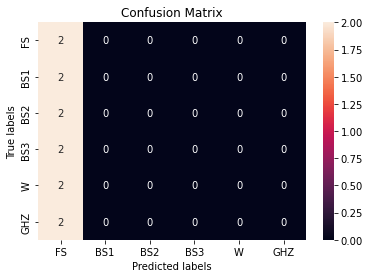

In [138]:
y_pred_new_test_set_1,x = evaluate_model(model_li5, x_new_test_set_1, y_new_test_set_1)
conf_mat = confusion_matrix_graph(y_new_test_set_1, y_pred_new_test_set_1)

#y_pred_new_test_set_1,x = evaluate_model(model_li5, x_test, y_test)
#conf_mat = confusion_matrix_graph(y_new_test_set_1, y_test)

In [80]:
acc_list_li5 = []
for i in range(0,35):
    x_test = x_new_test_set_1.iloc[[i],:]
    y_test = y_new_test_set_1.iloc[[i],:]
    pred, evaluate = evaluate_model(model_li5, x_test, y_test)
    acc_list_li5.append(evaluate[1])

1/1 [==============================] - 0s 21ms/step


IndexError: positional indexers are out-of-bounds

In [81]:
#model_li5_pred = pd.Dataframe({'ACCURACY':acc_list_li5})
#li5_df = pd.read_csv(test_expt_path_li5)
all_df['ACCURACY'] = acc_list_li5
all_df.iloc[:,1:]

,Rho_0_1_Real,Rho_0_2_Real,Rho_0_3_Real,Rho_0_4_Real,Rho_0_5_Real,Rho_0_6_Real,Rho_0_7_Real,Rho_1_0_Real,Rho_1_1_Real,Rho_1_2_Real,...,Rho_7_7_Imag,CODE,FS,BS1,BS2,BS3,W,GHZ,FIDELITY,ACCURACY
0,-0.0010,0.0040,0.0010,0.0891,-0.0031,0.0629,-0.0017,-0.0010,0.0019,-0.0000,...,0.0,0,1,0,0,0,0,0,0.9755,1.0
1,-0.0043,-0.0273,-0.0016,0.3209,-0.0075,0.0383,-0.0092,-0.0043,0.0009,-0.0002,...,0.0,0,1,0,0,0,0,0,0.9585,1.0
2,0.0060,-0.0023,-0.0032,0.0320,0.0290,0.0211,0.0138,0.0060,0.0031,0.0023,...,0.0,0,1,0,0,0,0,0,0.9329,1.0
3,0.0050,-0.0016,-0.0004,0.0046,0.0058,0.0136,0.0140,0.0050,0.0036,-0.0003,...,0.0,0,1,0,0,0,0,0,0.9482,1.0
4,-0.0018,-0.0004,0.0026,0.0019,0.0007,-0.0054,0.0165,-0.0018,0.0034,-0.0011,...,0.0,0,1,0,0,0,0,0,0.9848,1.0
5,0.0007,0.0002,0.0002,0.0035,0.0023,0.0024,0.0009,0.0007,0.0048,0.0007,...,0.0,1,0,1,0,0,0,0,0.9705,1.0
6,0.0031,0.0039,-0.0022,-0.0140,0.0004,-0.0325,-0.0069,0.0031,0.0023,-0.0003,...,0.0,1,0,1,0,0,0,0,0.9807,1.0
7,0.0067,0.0095,-0.0003,0.0765,0.0127,0.0222,-0.0004,0.0067,0.0059,0.0028,...,0.0,1,0,1,0,0,0,0,0.9381,1.0
8,0.0449,-0.0197,0.0239,0.0100,0.4384,-0.0083,0.0006,0.0449,0.0268,0.0009,...,0.0,1,0,1,0,0,0,0,0.9731,1.0
9,-0.0080,-0.0273,0.4364,0.0062,0.0155,0.0136,0.0099,-0.0080,0.0254,0.0134,...,0.0,1,0,1,0,0,0,0,0.9447,1.0


In [82]:
predictions = model_li5.predict(x_new_test_set_1)
pred_list = predictions.tolist()
# columns = ['PRED_FS','PRED_BS1','PRED_BS2','PRED_BS3','PRED_W','PRED_GHZ']
pred_df = pd.DataFrame(pred_list, columns = ['PRED_FS','PRED_BS1','PRED_BS2','PRED_BS3','PRED_W','PRED_GHZ'])

1/1 [==============================] - 0s 25ms/step


In [83]:
pred_df.shape

(30, 6)

In [84]:
all_df.shape

(30, 137)

In [85]:
all_df = all_df.reset_index()

In [86]:
all_df_1 = pd.concat([all_df, pred_df], axis = 1)

In [87]:
all_df_1.iloc[:,129:145]

,CODE,FS,BS1,BS2,BS3,W,GHZ,FIDELITY,ACCURACY,PRED_FS,PRED_BS1,PRED_BS2,PRED_BS3,PRED_W,PRED_GHZ
0,0,1,0,0,0,0,0,0.9755,1.0,0.599904,0.322362,0.007150,0.012796,0.056900,0.000888
1,0,1,0,0,0,0,0,0.9585,1.0,0.899760,0.048721,0.009353,0.003054,0.038542,0.000569
2,0,1,0,0,0,0,0,0.9329,1.0,0.901555,0.086520,0.001437,0.001334,0.008943,0.000211
3,0,1,0,0,0,0,0,0.9482,1.0,0.710464,0.224432,0.033884,0.000868,0.030137,0.000214
4,0,1,0,0,0,0,0,0.9848,1.0,0.939676,0.013775,0.011243,0.011645,0.012592,0.011069
5,1,0,1,0,0,0,0,0.9705,1.0,0.063603,0.834534,0.030398,0.000718,0.070677,0.000071
6,1,0,1,0,0,0,0,0.9807,1.0,0.026358,0.914758,0.001163,0.001865,0.055801,0.000055
7,1,0,1,0,0,0,0,0.9381,1.0,0.377223,0.568495,0.004358,0.002695,0.046848,0.000382
8,1,0,1,0,0,0,0,0.9731,1.0,0.010119,0.797563,0.086731,0.010040,0.090539,0.005009
9,1,0,1,0,0,0,0,0.9447,1.0,0.004209,0.978834,0.001765,0.002644,0.010916,0.001632
